# Capacidad de cupo y perfiles financieros de empresas calificadas

### Taller individual: ACP y K-Means

Machine Learning aplicado a Economía y Finanzas  
Facultad de Ciencias Económicas y Administrativas, Pontificia Universidad Javeriana Cali

| | |
|---|---|
| **Estudiante** | *[Nombre completo]* |
| **Fecha** | Noviembre de 2026 |
| **Repositorio** | *[enlace de GitHub]* |
| **Aplicación** | *[enlace de Streamlit]* |
| **Video** | *[enlace del video]* |

## Resumen

Cuando un banco o un proveedor decide cuánto crédito darle a una empresa, la primera pieza de evidencia son sus razones financieras. Este taller toma 2.694 estados financieros de 686 empresas estadounidenses calificadas entre 2010 y 2016 y se pregunta si esas razones esconden unas pocas dimensiones comunes y unos pocos perfiles de empresa que sirvan para graduar el cupo.

* El **ACP** reduce diez razones a tres ejes que conservan el **78,7 %** de la variación: rentabilidad, modelo de negocio (rotación frente a margen) y solidez de balance (liquidez frente a deuda de largo plazo).
* **K-Means** sobre esos tres ejes encuentra **tres perfiles** (silueta media 0,31): *margen alto y rotación baja* (39 %), *margen estrecho y rotación alta* (58 %) y *en pérdidas operativas* (3 %).
* La calificación crediticia **no entra al modelo**. Aun así, los tres grupos la ordenan: su rating mediano es **BBB+, BB+ y B+**, y la proporción con grado de inversión baja de 73 % a 48 % y a 23 %.
* De ahí sale una lectura de cupo en tres posturas: **amplio, condicionado y restringido**, que se afina con el eje de solidez de balance dentro de cada grupo.

## Contenido

1. Elección del tema y de los datos
2. Exploración y preparación
3. Análisis de componentes principales
4. Segmentación mediante K-Means
5. Sensibilidad de las decisiones
6. Verificación con el módulo de la aplicación
7. Aplicación en Streamlit
8. Discusión de resultados
9. Conclusiones

# 1. Elección del tema y de los datos

## 1.1 El problema: cuánto cupo darle a una empresa

El cupo de crédito es el monto máximo que una entidad está dispuesta a prestarle a un cliente. Para una empresa, ese número se decide en un comité que lee los estados financieros en bloques: si la empresa tiene liquidez para cubrir sus obligaciones de corto plazo, cuánto depende de la deuda, si sus márgenes dejan espacio para pagar intereses, qué tan eficiente es con sus activos y cuánto rinde lo invertido.

El problema práctico es que muchas razones cuentan la misma historia. Cinco márgenes distintos (bruto, operativo, EBITDA, antes de impuestos y neto) suben y bajan juntos; ROA y ROI también. Mirar dieciséis columnas una por una no deja ver el perfil de la empresa, y una política de cupo diseñada empresa por empresa no escala.

**Pregunta general.** ¿Las razones financieras de las empresas calificadas se pueden resumir en unas pocas dimensiones y agrupar en perfiles que correspondan a capacidades de cupo distintas?

| Pregunta específica | Herramienta |
|---|---|
| ¿Cuántas dimensiones bastan para describir la situación financiera de una empresa, y de qué razones están hechas? | ACP |
| ¿Cuántos perfiles financieros distintos sostiene la base, y en qué se diferencian? | K-Means |
| ¿Esos perfiles corresponden a calificaciones distintas, y qué postura de cupo sugiere cada uno? | Validación externa con el rating |

**Por qué es útil.** Un perfil le dice al analista *a qué empresas se parece* la que tiene enfrente antes de hacer el análisis completo. Permite fijar políticas diferenciadas (monto, garantías, covenants, frecuencia de revisión) por grupo en vez de una regla única para todos.

## 1.2 Fuente, cobertura y unidad de observación

**Fuente.** Conjunto público publicado en Kaggle con el nombre *Corporate Credit Rating with Financial Ratios* (archivo `corporateCreditRatingWithFinancialRatios.csv`). Une calificaciones crediticias emitidas por agencias a empresas que cotizan en Estados Unidos con dieciséis razones financieras de sus estados financieros. Las empresas se identifican con el CIK, el número de registro de la SEC.

**Cobertura.**

* 7.805 calificaciones emitidas entre abril de 2010 y diciembre de 2016.
* 686 empresas (CIK distintos) de 12 sectores.
* 7 agencias: Egan-Jones (36 %), Standard & Poor's (36 %), Moody's (21 %), Fitch (6 %), DBRS, Japan Credit Rating Agency y HR Ratings de México.
* Calificaciones en escala de letras, de AAA a D, y una variable binaria de grado de inversión.

**Unidad de observación.** En el archivo, cada fila es *una calificación*: la misma empresa con los mismos estados financieros aparece varias veces cuando la califican varias agencias o en varias fechas. Como lo que se quiere agrupar son perfiles financieros, la unidad de análisis es **un estado financiero de una empresa** (empresa-periodo). Después de esa consolidación quedan 2.694 observaciones (sección 2.4).

**Datos sensibles.** La información es pública (estados financieros reportados a la SEC y calificaciones publicadas). No contiene datos personales.

## 1.3 Diccionario de variables

| Variable original | Nombre en el análisis | Familia | Qué mide | Uso |
|---|---|---|---|---|
| Rating Agency | Agencia | Identificación | Agencia que emitió la calificación | Descriptiva |
| Corporation, Ticker, CIK | Empresa | Identificación | Nombre, símbolo bursátil y registro SEC | Identificador, no entra |
| Rating | Rating | Calificación | Letra de AAA a D | **Solo validación** |
| Binary Rating | Grado de inversión | Calificación | 1 si la calificación es BBB- o mejor | **Solo validación** |
| Rating Date | Fecha | Identificación | Fecha de la calificación | Descriptiva |
| SIC Code, Sector | Sector | Identificación | Código industrial y sector | Descriptiva |
| Current Ratio | Razón corriente | Liquidez | Activo corriente / pasivo corriente | Modelo |
| Long-term Debt / Capital | Deuda LP / capital | Apalancamiento | Deuda de largo plazo / (deuda LP + patrimonio) | Modelo |
| Debt/Equity Ratio | Deuda / patrimonio | Apalancamiento | Deuda total / patrimonio | Excluida (2.6) |
| Gross Margin | Margen bruto (%) | Márgenes | Utilidad bruta / ventas | Modelo |
| Operating Margin | Margen operativo (%) | Márgenes | Utilidad operativa / ventas | Modelo |
| EBIT Margin | Margen EBIT (%) | Márgenes | EBIT / ventas | Excluida (2.6) |
| EBITDA Margin | Margen EBITDA (%) | Márgenes | EBITDA / ventas | Modelo |
| Pre-Tax Profit Margin | Margen antes de impuestos (%) | Márgenes | Utilidad antes de impuestos / ventas | Modelo |
| Net Profit Margin | Margen neto (%) | Márgenes | Utilidad neta / ventas | Modelo |
| Asset Turnover | Rotación de activos | Eficiencia | Ventas / activos totales | Modelo |
| ROE - Return On Equity | ROE (%) | Rentabilidad | Utilidad neta / patrimonio | Excluida (2.6) |
| Return On Tangible Equity | Rentab. patrimonio tangible (%) | Rentabilidad | Utilidad neta / patrimonio tangible | Excluida (2.6) |
| ROA - Return On Assets | ROA (%) | Rentabilidad | Utilidad neta / activos | Modelo |
| ROI - Return On Investment | ROI (%) | Rentabilidad | Utilidad / capital invertido | Modelo |
| Operating Cash Flow Per Share | Flujo operativo por acción | Flujo de caja | Flujo de caja operativo / acciones | Excluida (2.6) |
| Free Cash Flow Per Share | Flujo libre por acción | Flujo de caja | Flujo de caja libre / acciones | Excluida (2.6) |

Las definiciones son las estándar de análisis financiero; la fuente no publica la fórmula exacta de cada razón.

## 1.4 Limitaciones de la fuente

* **Empresas grandes y listadas.** Solo hay empresas que cotizan en Estados Unidos y que alguna agencia califica. Los resultados no se trasladan sin más a pymes ni a empresas colombianas, que son la mayoría de los clientes de un banco local.
* **Ventana 2010–2016.** Es un periodo de recuperación posterior a la crisis financiera con tasas bajas; los perfiles pueden ser distintos en otro ciclo.
* **Fórmulas no documentadas.** La fuente no explica cómo se calculó cada razón. Las cifras por acción, por ejemplo, tienen una distribución difícil de interpretar.
* **Fecha aproximada del estado financiero.** El archivo trae la fecha de la calificación, no la del cierre contable. El año se aproxima con la fecha de la calificación más reciente.
* **Observaciones no independientes.** Una empresa aparece en varios años, así que sus observaciones se parecen entre sí.
* **Errores de formato.** 1.707 líneas del CSV están mal formadas y hay que repararlas al leer (sección 2.1).

## 1.5 Por qué ACP y K-Means son pertinentes aquí

* **Hay redundancia que el ACP puede resumir.** Los márgenes operativo, EBITDA, antes de impuestos y neto tienen correlaciones de 0,63 a 0,93 entre sí, y ROA y ROI de 0,92 (sección 2.8). Un analista ya piensa en pocas dimensiones (rentabilidad, eficiencia, solvencia); el ACP deja que sean los datos los que digan cuáles son y cuánto pesa cada una.
* **No hay una etiqueta de cupo.** Ningún archivo dice cuánto cupo merece cada empresa. K-Means agrupa sin etiqueta y resume cada grupo en un centro, que es la *empresa típica* del perfil. Ese centro también permite ubicar a una empresa nueva por cercanía.
* **El rating sirve de prueba independiente.** La calificación de las agencias es un juicio experto sobre la capacidad de pago. Al dejarla fuera del modelo, se puede comprobar después si los grupos formados solo con razones financieras corresponden a calidades crediticias distintas. Si lo hacen, la segmentación captura algo real sobre la capacidad de endeudamiento.

# 2. Exploración y preparación

El código usa pandas, numpy, scikit-learn, matplotlib y seaborn. El archivo de datos está en la carpeta `data/` del repositorio.

> **Si trabajas en Google Colab:** sube a la sesión `analisis.py` y la carpeta `data/` con el CSV, o clona el repositorio con `!git clone <enlace>` y entra a la carpeta con `%cd`.

In [1]:
import csv
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

RUTA = "data/corporateCreditRatingWithFinancialRatios.csv"
SEMILLA = 42

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Identidad gráfica del proyecto
TINTA, VERDE, OCRE, VINO, GRIS = "#1D2B36", "#2E5E4E", "#C8963E", "#A63D40", "#8A9A94"

def pct(x, d=1):  # número con coma decimal, para los textos de los gráficos
    return f"{x:.{d}f}".replace(".", ",")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "xtick.color": TINTA,
    "ytick.color": TINTA, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlecolor": TINTA, "font.size": 10,
})

## 2.1 Carga de los datos y reparación del formato

Un `pd.read_csv` directo falla:

In [2]:
try:
    pd.read_csv(RUTA)
except Exception as e:
    print(type(e).__name__, "->", e)

ParserError -> Error tokenizing data. C error: Expected 25 fields in line 1996, saw 26



La línea 1.996 tiene 26 campos en vez de 25. Al revisar el archivo aparecen dos defectos:

1. **Coma dentro del nombre de una agencia.** `Japan Credit Rating Agency,Ltd.` viene sin comillas, y la coma parte el nombre en dos columnas.
2. **Líneas completas entre comillas.** 1.685 filas vienen enteras encerradas en comillas, con las comillas internas duplicadas. Un lector de CSV las ve como una sola columna.

La función siguiente lee línea por línea, deshace el encierro y vuelve a unir el nombre de la agencia. No se descarta ninguna fila.

In [3]:
RATIOS = ["Current Ratio", "Long-term Debt / Capital", "Debt/Equity Ratio",
          "Gross Margin", "Operating Margin", "EBIT Margin", "EBITDA Margin",
          "Pre-Tax Profit Margin", "Net Profit Margin", "Asset Turnover",
          "ROE - Return On Equity", "Return On Tangible Equity",
          "ROA - Return On Assets", "ROI - Return On Investment",
          "Operating Cash Flow Per Share", "Free Cash Flow Per Share"]

ESCALA_RATING = {"AAA": 1, "AA+": 2, "AA": 3, "AA-": 4, "A+": 5, "A": 6, "A-": 7,
                 "BBB+": 8, "BBB": 9, "BBB-": 10, "BB+": 11, "BB": 12, "BB-": 13,
                 "B+": 14, "B": 15, "B-": 16, "CCC+": 17, "CCC": 18, "CCC-": 19,
                 "CC+": 20, "CC": 20, "C": 21, "D": 22}
PUNTAJE_A_RATING = {v: k for k, v in ESCALA_RATING.items() if k != "CC+"}

def cargar_datos(ruta):
    with open(ruta, newline="", encoding="utf-8") as f:
        lineas = f.read().splitlines()
    encabezado = next(csv.reader([lineas[0]]))
    filas, registro = [], Counter()
    for linea in lineas[1:]:
        if not linea.strip():
            continue
        campos = next(csv.reader([linea]))
        if len(campos) == 1:                      # línea completa entre comillas
            campos = next(csv.reader([campos[0]]))
            registro["líneas entre comillas reparadas"] += 1
        if len(campos) == len(encabezado) + 1 and campos[1].strip() == "Ltd.":
            campos = [campos[0] + "," + campos[1]] + campos[2:]
            registro["coma en el nombre de la agencia reparada"] += 1
        if len(campos) != len(encabezado):
            registro["líneas descartadas"] += 1
            continue
        filas.append(campos)
    df = pd.DataFrame(filas, columns=encabezado)
    for c in RATIOS + ["CIK", "Binary Rating", "SIC Code"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["Rating Date"] = pd.to_datetime(df["Rating Date"], errors="coerce")
    df["Puntaje rating"] = df["Rating"].map(ESCALA_RATING)
    return df, dict(registro)

df, registro = cargar_datos(RUTA)
print(registro)
print("Dimensión:", df.shape)

{'líneas entre comillas reparadas': 1685, 'coma en el nombre de la agencia reparada': 22}
Dimensión: (7805, 26)


## 2.2 Estructura de la base

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7805 entries, 0 to 7804
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Rating Agency                  7805 non-null   str           
 1   Corporation                    7805 non-null   str           
 2   Rating                         7805 non-null   str           
 3   Rating Date                    7805 non-null   datetime64[us]
 4   CIK                            7805 non-null   int64         
 5   Binary Rating                  7805 non-null   int64         
 6   SIC Code                       7805 non-null   float64       
 7   Sector                         7805 non-null   str           
 8   Ticker                         7805 non-null   str           
 9   Current Ratio                  7805 non-null   float64       
 10  Long-term Debt / Capital       7805 non-null   float64       
 11  Debt/Equity Ratio           

In [5]:
df.head()

,Rating Agency,Corporation,Rating,Rating Date,CIK,Binary Rating,SIC Code,Sector,Ticker,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share,Puntaje rating
0,Standard & Poor's Ratings Services,American States Water Co.,A-,2010-07-30,1056903,1,"4,941.00",Utils,AWR,1.15,0.46,0.88,77.62,19.48,19.48,28.98,13.61,8.32,0.32,8.17,8.20,2.64,4.45,2.00,-0.13,7
1,Standard & Poor's Ratings Services,Automatic Data Processing Inc.,AAA,2010-09-16,8670,1,"7,374.00",BusEq,ADP,1.11,0.01,0.01,43.66,19.83,19.83,23.94,20.87,13.57,0.33,22.04,47.29,4.49,21.88,0.25,0.31,1
2,Standard & Poor's Ratings Services,Avnet Inc.,BBB-,2010-11-23,8858,1,"5,065.00",Shops,AVT,1.93,0.29,0.43,11.90,3.32,3.32,3.63,3.05,2.14,2.46,13.64,16.80,5.27,9.65,-7.61,-7.32,10
3,Standard & Poor's Ratings Services,California Water Service Co.,AA-,2010-06-29,1035201,1,"4,941.00",Utils,CWT,0.84,0.47,0.95,64.51,18.45,18.45,27.94,15.11,9.02,0.29,9.64,9.70,2.66,5.10,1.74,-0.90,4
4,Standard & Poor's Ratings Services,Cardinal Health Inc.,A,2010-07-14,721371,1,"5,122.00",Shops,CAH,1.29,0.26,0.40,3.84,1.33,1.33,1.58,1.23,0.65,4.93,11.13,19.42,2.94,8.18,1.97,2.42,6


La base tiene **7.805 calificaciones y 25 columnas originales** (más el puntaje numérico del rating que se agrega para el análisis): nueve de identificación y calificación, y dieciséis razones financieras numéricas. Las fechas van de abril de 2010 a diciembre de 2016.

El puntaje convierte la letra en un número de 1 (AAA) a 22 (D). Un puntaje de 10 o menos (BBB- o mejor) es **grado de inversión**.

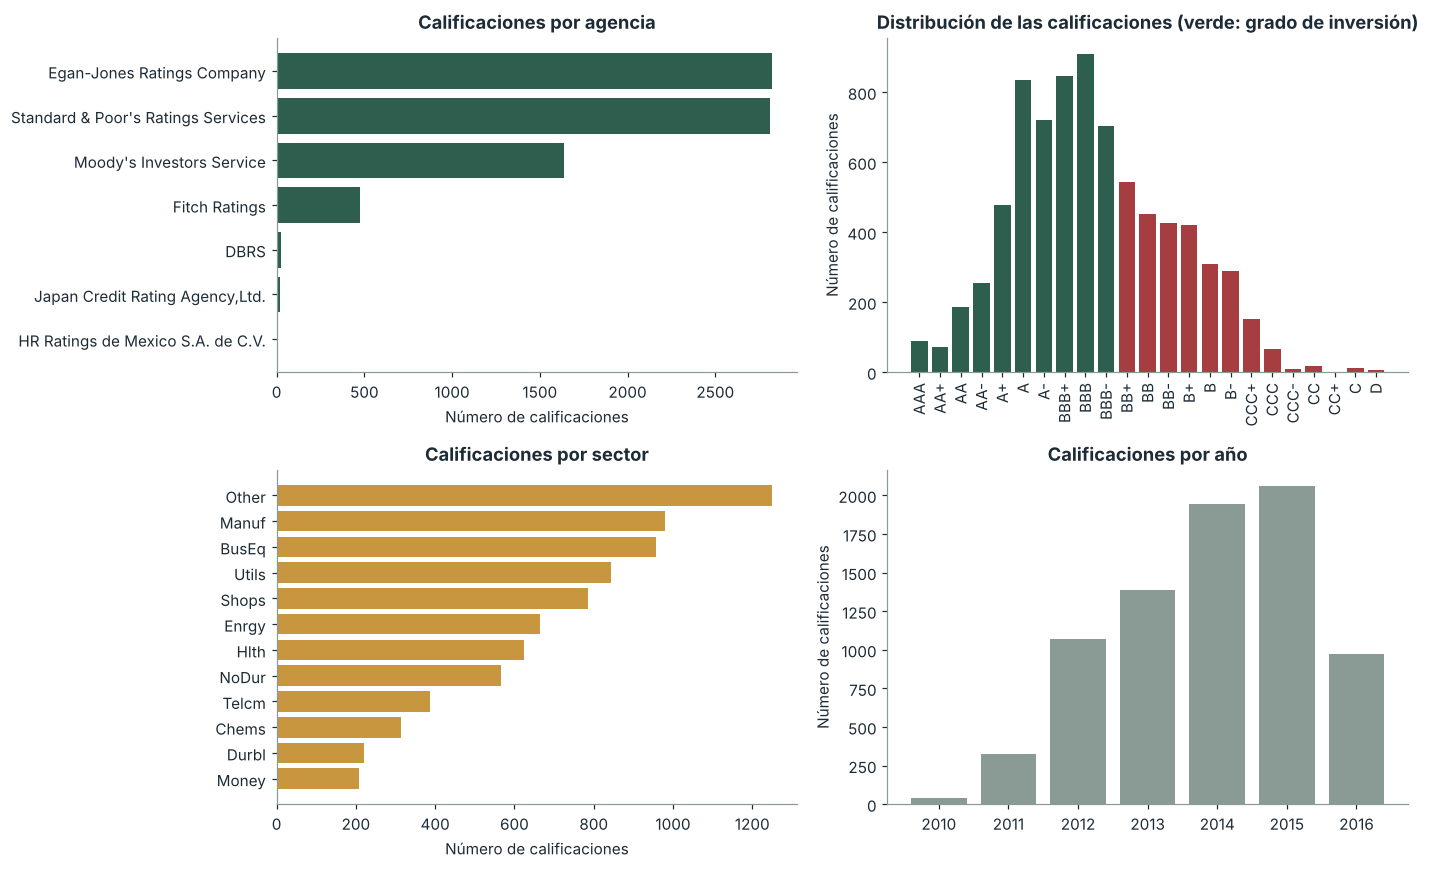

Grado de inversión en las calificaciones: 65.3%


In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

agencias = df["Rating Agency"].value_counts()
ax[0, 0].barh(agencias.index[::-1], agencias.values[::-1], color=VERDE)
ax[0, 0].set_title("Calificaciones por agencia")
ax[0, 0].set_xlabel("Número de calificaciones")

orden = sorted(df["Rating"].dropna().unique(), key=lambda r: ESCALA_RATING[r])
cuenta = df["Rating"].value_counts().reindex(orden)
colores = [VERDE if ESCALA_RATING[r] <= 10 else VINO for r in orden]
ax[0, 1].bar(cuenta.index, cuenta.values, color=colores)
ax[0, 1].set_title("Distribución de las calificaciones (verde: grado de inversión)")
ax[0, 1].set_ylabel("Número de calificaciones")
ax[0, 1].tick_params(axis="x", rotation=90)

sect = df["Sector"].value_counts()
ax[1, 0].barh(sect.index[::-1], sect.values[::-1], color=OCRE)
ax[1, 0].set_title("Calificaciones por sector")
ax[1, 0].set_xlabel("Número de calificaciones")

anio = df["Rating Date"].dt.year.value_counts().sort_index()
ax[1, 1].bar(anio.index.astype(str), anio.values, color=GRIS)
ax[1, 1].set_title("Calificaciones por año")
ax[1, 1].set_ylabel("Número de calificaciones")

plt.tight_layout(); plt.show()
print(f"Grado de inversión en las calificaciones: {(df['Puntaje rating'] <= 10).mean():.1%}")

Las calificaciones se concentran entre A y BB; casi dos de cada tres calificaciones son grado de inversión. Egan-Jones y S&P emiten siete de cada diez. Todos los sectores tienen al menos 200 calificaciones, y 2010 tiene pocas observaciones porque la base empieza en abril.

## 2.3 Valores faltantes

In [7]:
faltantes = df.isna().sum()
print("Celdas faltantes en toda la base:", int(faltantes.sum()))
faltantes[faltantes > 0]

Celdas faltantes en toda la base: 0


Series([], dtype: int64)

Después de reparar el formato no hay valores faltantes: no hace falta imputar. Las 1.707 líneas reparadas habrían aparecido como faltantes o como errores de lectura si se hubieran forzado con `on_bad_lines="skip"`, lo que habría borrado el 22 % de la base sin avisar.

## 2.4 Duplicados y unidad de análisis

In [8]:
print("Filas idénticas en todas las columnas:", df.duplicated().sum())
dup = df.duplicated(subset=["CIK"] + RATIOS)
print("Filas que repiten empresa y razones financieras:", dup.sum(), f"({dup.mean():.1%})")

ejemplo = df[df["Ticker"] == "AVT"].sort_values("Rating Date")[
    ["Rating Agency", "Rating", "Rating Date", "Current Ratio", "Net Profit Margin", "ROA - Return On Assets"]]
ejemplo.head(8)

Filas idénticas en todas las columnas: 0
Filas que repiten empresa y razones financieras: 5111 (65.5%)


,Rating Agency,Rating,Rating Date,Current Ratio,Net Profit Margin,ROA - Return On Assets
2,Standard & Poor's Ratings Services,BBB-,2010-11-23,1.93,2.14,5.27
67,Standard & Poor's Ratings Services,BBB-,2011-11-08,1.84,2.52,6.75
468,Moody's Investors Service,BBB-,2012-06-15,1.84,2.52,6.75
466,Standard & Poor's Ratings Services,BBB-,2012-11-16,1.72,2.21,5.58
467,Standard & Poor's Ratings Services,BBB-,2012-11-19,1.72,2.21,5.58
469,Moody's Investors Service,BBB-,2012-11-20,1.72,2.21,5.58
470,Fitch Ratings,BBB-,2012-11-27,1.72,2.21,5.58
1499,Egan-Jones Ratings Company,BBB,2013-07-02,1.73,1.77,4.30


No hay filas idénticas, pero el 65 % de las filas repite la empresa y **todas** sus razones financieras: es el mismo estado financiero calificado por otra agencia o en otra fecha. El ejemplo de Avnet muestra el mismo balance con varias calificaciones.

Si se dejaran así, una empresa calificada trece veces pesaría trece veces más que una calificada una vez, tanto en la varianza del ACP como en los centros de K-Means. La decisión es:

* **Una fila por empresa y juego de razones** (CIK + 16 razones).
* La calificación de esa fila es la **mediana** de las calificaciones que recibió, para no favorecer a ninguna agencia.
* El año es el de la calificación más reciente.

In [9]:
obs = (df.groupby(["CIK"] + RATIOS, as_index=False, sort=False)
         .agg(Empresa=("Corporation", "last"), Ticker=("Ticker", "first"),
              Sector=("Sector", "first"), Fecha=("Rating Date", "max"),
              Calificaciones=("Rating", "size"), Puntaje=("Puntaje rating", "median")))
obs["Rating mediano"] = obs["Puntaje"].apply(lambda p: PUNTAJE_A_RATING[int(np.clip(round(p), 1, 22))])
obs["Grado de inversión"] = (obs["Puntaje"] <= 10).astype(int)
obs["Año"] = obs["Fecha"].dt.year

print("Observaciones (empresa-periodo):", len(obs))
print("Empresas distintas:", obs["CIK"].nunique())
print("Calificaciones por observación: mediana", obs["Calificaciones"].median(), "| máximo", obs["Calificaciones"].max())
print(f"Grado de inversión en las observaciones: {obs['Grado de inversión'].mean():.1%}")

Observaciones (empresa-periodo): 2694
Empresas distintas: 686
Calificaciones por observación: mediana 2.0 | máximo 13
Grado de inversión en las observaciones: 57.3%


Quedan **2.694 observaciones de 686 empresas**. Cada estado financiero recibió entre 1 y 13 calificaciones (mediana 2). La proporción con grado de inversión baja de 65 % a 57 %, porque las empresas grandes y sólidas eran las que más calificaciones acumulaban.

## 2.5 Estadísticas descriptivas de las razones

In [10]:
NOMBRES = {"Current Ratio": "Razón corriente", "Long-term Debt / Capital": "Deuda LP / capital",
           "Debt/Equity Ratio": "Deuda / patrimonio", "Gross Margin": "Margen bruto (%)",
           "Operating Margin": "Margen operativo (%)", "EBIT Margin": "Margen EBIT (%)",
           "EBITDA Margin": "Margen EBITDA (%)", "Pre-Tax Profit Margin": "Margen antes de impuestos (%)",
           "Net Profit Margin": "Margen neto (%)", "Asset Turnover": "Rotación de activos",
           "ROE - Return On Equity": "ROE (%)", "Return On Tangible Equity": "Rentab. patrimonio tangible (%)",
           "ROA - Return On Assets": "ROA (%)", "ROI - Return On Investment": "ROI (%)",
           "Operating Cash Flow Per Share": "Flujo operativo por acción",
           "Free Cash Flow Per Share": "Flujo libre por acción"}

desc = obs[RATIOS].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["asimetría"] = obs[RATIOS].skew()
desc.index = [NOMBRES[v] for v in desc.index]
desc.drop(columns="count")

,mean,std,min,1%,25%,50%,75%,99%,max,asimetría
Razón corriente,1.94,1.75,0.17,0.47,1.11,1.56,2.25,7.87,34.08,7.76
Deuda LP / capital,0.49,3.73,-86.36,0.00,0.28,0.42,0.55,1.53,171.50,31.13
Deuda / patrimonio,-0.71,47.08,"-1,473.10",-15.66,0.39,0.74,1.21,23.25,194.38,-24.82
Margen bruto (%),41.86,23.86,-87.68,4.12,22.23,38.87,59.09,100.00,100.00,0.40
Margen operativo (%),11.16,24.51,-461.79,-56.52,5.67,11.62,18.63,48.44,93.99,-8.91
Margen EBIT (%),11.21,24.53,-461.79,-56.52,5.68,11.66,18.72,48.92,93.99,-8.90
Margen EBITDA (%),19.64,24.67,-360.82,-35.73,10.42,17.71,29.84,68.53,286.49,-4.97
Margen antes de impuestos (%),8.18,26.94,-476.01,-75.57,3.35,9.07,15.74,47.72,221.29,-7.84
Margen neto (%),5.47,23.92,-414.82,-73.05,2.28,6.40,11.62,41.12,219.39,-7.97
Rotación de activos,0.88,0.71,0.07,0.14,0.41,0.68,1.09,3.50,8.50,2.75


Tres rasgos se leen en la tabla:

* **Colas muy largas.** La media y la mediana se separan en casi todas las razones. El ROE va de −11.258 % a 7.038 %; la deuda LP sobre capital llega a 171 cuando su rango natural está entre 0 y 1. El 98 % central de cada razón, en cambio, es razonable (columnas 1 % y 99 %).
* **Asimetrías extremas.** Varias razones tienen asimetrías por encima de 10 en valor absoluto. Con esas colas, unas pocas empresas dominarían la varianza del ACP y K-Means les dedicaría un grupo entero.
* **Escalas distintas.** Los márgenes están en porcentaje (decenas), la razón corriente y la rotación en veces (unidades). Sin estandarizar, los márgenes ganarían por unidad de medida, no por importancia.

## 2.6 Selección de variables

In [11]:
print("Margen operativo = margen EBIT en", f"{(obs['Operating Margin'] == obs['EBIT Margin']).mean():.1%}", "de las observaciones")
print("Correlación margen operativo vs margen EBIT:", round(obs["Operating Margin"].corr(obs["EBIT Margin"]), 4))

neg = obs["Debt/Equity Ratio"] < 0
print(f"\nPatrimonio negativo (deuda/patrimonio < 0): {neg.sum()} observaciones ({neg.mean():.1%})")
roe_engana = (neg & (obs["ROE - Return On Equity"] > 0) & (obs["Net Profit Margin"] < 0)).sum()
print("De ellas, con pérdidas pero ROE positivo:", roe_engana)
print("Rango de la rentabilidad del patrimonio tangible:",
      obs["Return On Tangible Equity"].min().round(0), "a", obs["Return On Tangible Equity"].max().round(0))

obs.loc[neg & (obs["Net Profit Margin"] < 0),
        ["Empresa", "Debt/Equity Ratio", "Net Profit Margin", "ROE - Return On Equity", "Rating mediano"]].head(5)

Margen operativo = margen EBIT en 97.4% de las observaciones
Correlación margen operativo vs margen EBIT: 0.9997

Patrimonio negativo (deuda/patrimonio < 0): 112 observaciones (4.2%)
De ellas, con pérdidas pero ROE positivo: 29
Rango de la rentabilidad del patrimonio tangible: -14023.0 a 9883.0


,Empresa,Debt/Equity Ratio,Net Profit Margin,ROE - Return On Equity,Rating mediano
103,Eastman Kodak Co.,-1.16,-11.46,49.77,CC
253,United Rentals Inc.,-146.45,-1.16,110.00,B
327,Berry Global Group Inc.,-10.26,-6.56,64.03,CCC
339,Bright Horizons Family Solutions LLC,-3.88,-6.99,-2.31,BB
344,Burlington Resources Finance Company,-14.54,-3.33,5.65,A


Las razones se seleccionan pensando en la pregunta (capacidad de pago y de endeudamiento) y en si su valor se puede comparar entre empresas. Entran **diez razones**; seis quedan fuera por razones concretas:

| Variable excluida | Motivo |
|---|---|
| Margen EBIT | Coincide con el margen operativo en el 97,4 % de las observaciones (correlación 0,9997). Entrar con las dos contaría dos veces el mismo dato. |
| Deuda / patrimonio | Tiene el patrimonio en el denominador. Con patrimonio negativo (112 observaciones, 4,2 %) el signo se invierte: una empresa insolvente aparece como *poco* endeudada. La deuda LP / capital mide el apalancamiento sin ese defecto, porque crece cuando el patrimonio se vuelve negativo. |
| ROE | Mismo problema de signo: 29 empresas con patrimonio negativo y pérdidas muestran un ROE positivo, como las de la tabla de arriba. ROA y ROI miden la rentabilidad sin depender del patrimonio. |
| Rentabilidad del patrimonio tangible | Mismo problema, con valores entre −14.023 % y 9.883 %. |
| Flujo operativo y flujo libre por acción | Están expresados *por acción*: dependen del número de acciones en circulación, que no tiene relación con la capacidad de pago. Un *split* cambia el indicador sin que cambie la empresa. |

Las diez razones del modelo cubren las cinco familias que mira un comité de crédito:

* **Liquidez:** razón corriente.
* **Apalancamiento:** deuda LP / capital.
* **Márgenes:** bruto, operativo, EBITDA, antes de impuestos y neto.
* **Eficiencia:** rotación de activos.
* **Rentabilidad:** ROA y ROI.

El taller pide al menos cuatro variables cuantitativas con variación y sentido analítico; aquí hay diez.

In [12]:
VARIABLES = ["Current Ratio", "Long-term Debt / Capital", "Gross Margin", "Operating Margin",
             "EBITDA Margin", "Pre-Tax Profit Margin", "Net Profit Margin", "Asset Turnover",
             "ROA - Return On Assets", "ROI - Return On Investment"]
ETIQ = [NOMBRES[v] for v in VARIABLES]
X = obs[VARIABLES].astype(float)
X.shape

(2694, 10)

## 2.7 Valores extremos y winsorización

Los valores extremos de las razones no son errores de digitación: son empresas con patrimonio casi nulo, ventas muy pequeñas o pérdidas excepcionales. Borrarlas sacaría del análisis justo a las empresas más riesgosas. La alternativa estándar en finanzas es **winsorizar**: llevar los valores por debajo del percentil 1 al percentil 1, y los que están por encima del percentil 99 al percentil 99. La empresa se queda en la base y conserva su posición relativa, pero deja de arrastrar la varianza.

In [13]:
Q = 0.01
inf, sup = X.quantile(Q), X.quantile(1 - Q)
Xw = X.clip(inf, sup, axis=1)

tabla_w = pd.DataFrame({
    "Percentil 1": inf, "Percentil 99": sup,
    "Mín. original": X.min(), "Máx. original": X.max(),
    "Valores recortados": ((X < inf) | (X > sup)).sum(),
    "Asimetría antes": X.skew(), "Asimetría después": Xw.skew(),
})
tabla_w.index = ETIQ
tabla_w

,Percentil 1,Percentil 99,Mín. original,Máx. original,Valores recortados,Asimetría antes,Asimetría después
Razón corriente,0.47,7.87,0.17,34.08,54,7.76,2.34
Deuda LP / capital,0.00,1.53,-86.36,171.50,54,31.13,1.30
Margen bruto (%),4.12,100.00,-87.68,100.00,27,0.40,0.50
Margen operativo (%),-56.52,48.44,-461.79,93.99,54,-8.91,-1.15
Margen EBITDA (%),-35.73,68.53,-360.82,286.49,54,-4.97,0.33
Margen antes de impuestos (%),-75.57,47.72,-476.01,221.29,54,-7.84,-1.84
Margen neto (%),-73.05,41.12,-414.82,219.39,54,-7.97,-2.40
Rotación de activos,0.14,3.50,0.07,8.50,54,2.75,1.77
ROA (%),-23.89,20.56,-226.44,114.72,54,-7.50,-1.19
ROI (%),-41.25,41.00,-745.45,466.67,54,-11.66,-0.89


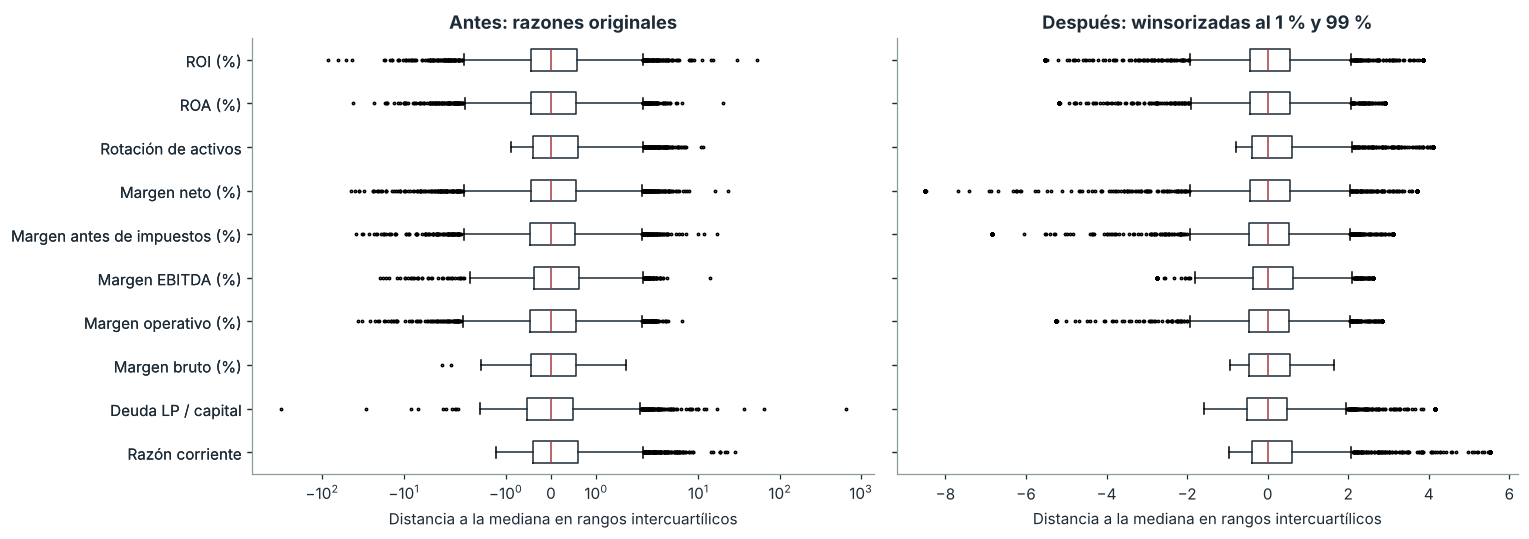

In [14]:
Zc = (X - X.median()) / (X.quantile(.75) - X.quantile(.25))       # escala robusta, solo para comparar
Zw = (Xw - Xw.median()) / (Xw.quantile(.75) - Xw.quantile(.25))
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a, Z_, t in [(ax[0], Zc, "Antes: razones originales"), (ax[1], Zw, "Después: winsorizadas al 1 % y 99 %")]:
    a.boxplot([Z_[v] for v in VARIABLES], orientation="horizontal", tick_labels=ETIQ, flierprops=dict(marker=".", markersize=3, color=GRIS),
              medianprops=dict(color=VINO), boxprops=dict(color=TINTA), whiskerprops=dict(color=TINTA))
    a.set_title(t); a.set_xlabel("Distancia a la mediana en rangos intercuartílicos")
ax[0].set_xscale("symlog")
plt.tight_layout(); plt.show()

Antes de la winsorización (panel izquierdo, en escala logarítmica simétrica) algunas empresas están a cientos de rangos intercuartílicos de la mediana. Después (panel derecho), las colas siguen ahí, pero acotadas. Se recortaron 54 valores por variable (27 en el margen bruto, que tiene un techo natural de 100 %), y la asimetría de cada razón bajó a valores manejables.

## 2.8 Correlaciones entre las razones

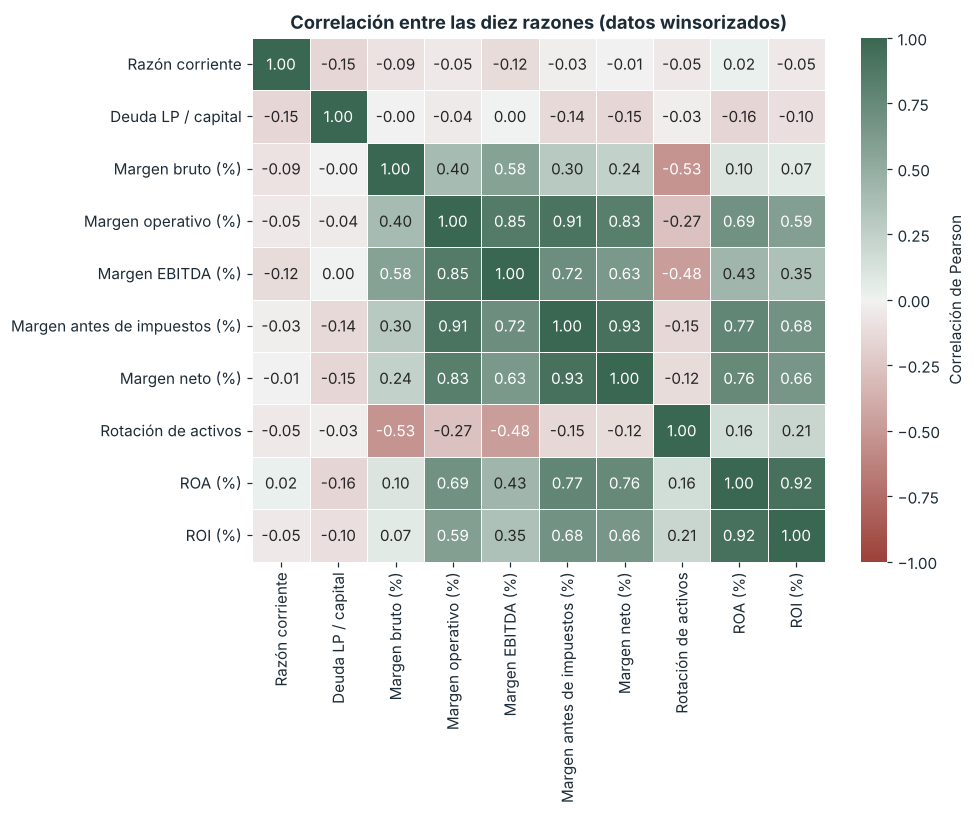

In [15]:
corr = Xw.corr()
corr.index = corr.columns = ETIQ
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(15, 150, s=60, l=40, as_cmap=True),
            center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Correlación entre las diez razones (datos winsorizados)")
plt.tight_layout(); plt.show()

La matriz anticipa la estructura que va a encontrar el ACP:

* **Un bloque de rentabilidad.** Margen operativo, antes de impuestos y neto tienen correlaciones de 0,83 a 0,93; ROA y ROI, 0,92 entre sí y de 0,59 a 0,77 con los márgenes operativo, antes de impuestos y neto. Es una sola historia contada varias veces.
* **Margen frente a rotación.** La rotación de activos se correlaciona negativamente con el margen bruto (−0,53) y el margen EBITDA (−0,48). Es la identidad de DuPont: se puede ganar con margen alto y pocas ventas por activo (servicios públicos, farmacéuticas) o con margen estrecho y mucha rotación (comercio).
* **Liquidez y deuda van por su lado.** La razón corriente y la deuda LP / capital casi no se correlacionan con los márgenes; entre ellas la correlación es −0,15. El balance es una dimensión aparte del estado de resultados.

Esta redundancia es la que justifica el ACP: diez columnas, pero claramente menos de diez historias.

## 2.9 Estandarización

ACP y K-Means trabajan con varianzas y distancias. Si los márgenes entran en porcentaje y la rotación en veces, el margen domina por la unidad. Se estandariza cada razón a media 0 y desviación 1, lo que equivale a hacer el ACP sobre la matriz de correlaciones.

In [16]:
escalador = StandardScaler().fit(Xw)
Z = escalador.transform(Xw)
pd.DataFrame({"Media": Z.mean(axis=0), "Desviación": Z.std(axis=0)}, index=ETIQ).round(3)

,Media,Desviación
Razón corriente,0.00,1.00
Deuda LP / capital,0.00,1.00
Margen bruto (%),0.00,1.00
Margen operativo (%),0.00,1.00
Margen EBITDA (%),-0.00,1.00
Margen antes de impuestos (%),0.00,1.00
Margen neto (%),-0.00,1.00
Rotación de activos,-0.00,1.00
ROA (%),0.00,1.00
ROI (%),0.00,1.00


**Una decisión distinta a la del cuaderno de clase.** En clase, además de estandarizar, se normalizó cada fila a longitud 1, porque la pregunta era de *estilo* de uso de la tarjeta. Aquí la pregunta es de *nivel*: un margen neto de −37 % es mucho peor que uno de −2 %, y esa magnitud es justo lo que importa para el cupo. Normalizar la fila borraría esa diferencia. Por eso no se normaliza; la sección 5 muestra qué pasa si se hace.

# 3. Análisis de componentes principales

## 3.1 Varianza explicada

Se ajusta el ACP con los diez componentes posibles. El signo de un componente es arbitrario: se orienta cada uno para que su carga más grande sea positiva, de modo que la lectura no cambie entre corridas. Cambiar el signo no altera la varianza ni las distancias.

In [17]:
acp = PCA().fit(Z)
cargas = pd.DataFrame(acp.components_.T, index=VARIABLES, columns=[f"CP{i+1}" for i in range(len(VARIABLES))])
signos = np.sign(cargas.apply(lambda c: c[c.abs().idxmax()])).values
cargas = cargas * signos
puntajes = acp.transform(Z) * signos

varianza = pd.DataFrame({
    "Valor propio": acp.explained_variance_,
    "Varianza explicada (%)": acp.explained_variance_ratio_ * 100,
    "Acumulada (%)": np.cumsum(acp.explained_variance_ratio_) * 100,
}, index=cargas.columns)
varianza

,Valor propio,Varianza explicada (%),Acumulada (%)
CP1,4.79,47.93,47.93
CP2,1.92,19.15,67.08
CP3,1.16,11.60,78.68
CP4,0.84,8.39,87.08
CP5,0.52,5.24,92.31
CP6,0.35,3.51,95.82
CP7,0.23,2.34,98.17
CP8,0.08,0.82,98.98
CP9,0.06,0.59,99.58
CP10,0.04,0.42,100.00


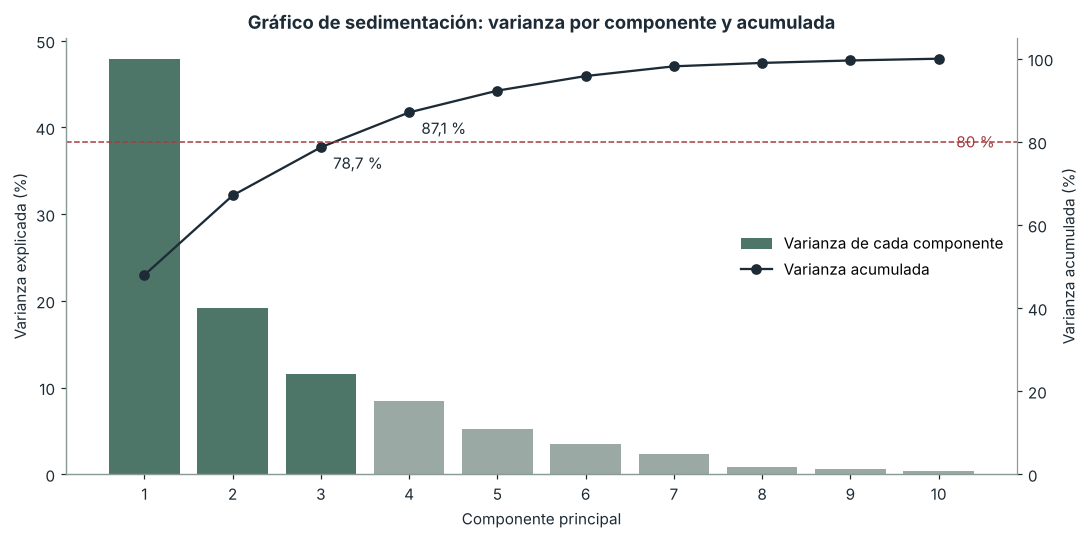

In [18]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(1, len(varianza) + 1)
ax1.bar(x, varianza["Varianza explicada (%)"], color=[VERDE if i < 3 else GRIS for i in range(len(x))], alpha=.85,
        label="Varianza de cada componente")
ax1.set_xlabel("Componente principal"); ax1.set_ylabel("Varianza explicada (%)"); ax1.set_xticks(x)
ax2 = ax1.twinx()
ax2.plot(x, varianza["Acumulada (%)"], "-o", color=TINTA, label="Varianza acumulada")
ax2.axhline(80, ls="--", color=VINO, lw=1); ax2.text(10.2, 80, "80 %", color=VINO, va="center")
ax2.set_ylabel("Varianza acumulada (%)"); ax2.set_ylim(0, 105); ax2.spines["right"].set_visible(True)
for i in [2, 3]:
    ax2.annotate(f"{pct(varianza['Acumulada (%)'].iloc[i])} %", (x[i], varianza["Acumulada (%)"].iloc[i]),
                 textcoords="offset points", xytext=(8, -14), color=TINTA)
ax1.set_title("Gráfico de sedimentación: varianza por componente y acumulada")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}"))
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right", frameon=False)
plt.tight_layout(); plt.show()

## 3.2 Cuántos componentes conservar

Se aplican tres criterios y se decide con los tres a la vista:

| Criterio | Qué dice | Resultado |
|---|---|---|
| Kaiser (valor propio > 1) | Un componente vale la pena si resume más que una variable original estandarizada | **3** componentes (4,79; 1,92; 1,16). El cuarto tiene 0,84 |
| Varianza acumulada ≥ 80 % | Conservar hasta resumir la mayor parte de la información | 3 componentes dan 78,7 %; hacen falta **4** para pasar el 80 % (87,1 %) |
| Codo del gráfico | Cortar donde la curva deja de caer con fuerza | La caída es fuerte hasta el **3** (11,6 %); del 4 en adelante cada componente aporta menos de 9 % |

**Decisión: tres componentes, que conservan el 78,7 % de la varianza.** Dos de los tres criterios coinciden, el cuarto componente resume menos que una sola razón original y, como se ve en 3.3, no tiene una lectura económica tan clara como los tres primeros. La cifra queda 1,3 puntos por debajo del 80 %; la sección 4.3 comprueba que agrupar con cuatro componentes produce prácticamente los mismos grupos.

## 3.3 Cargas: de qué está hecho cada eje

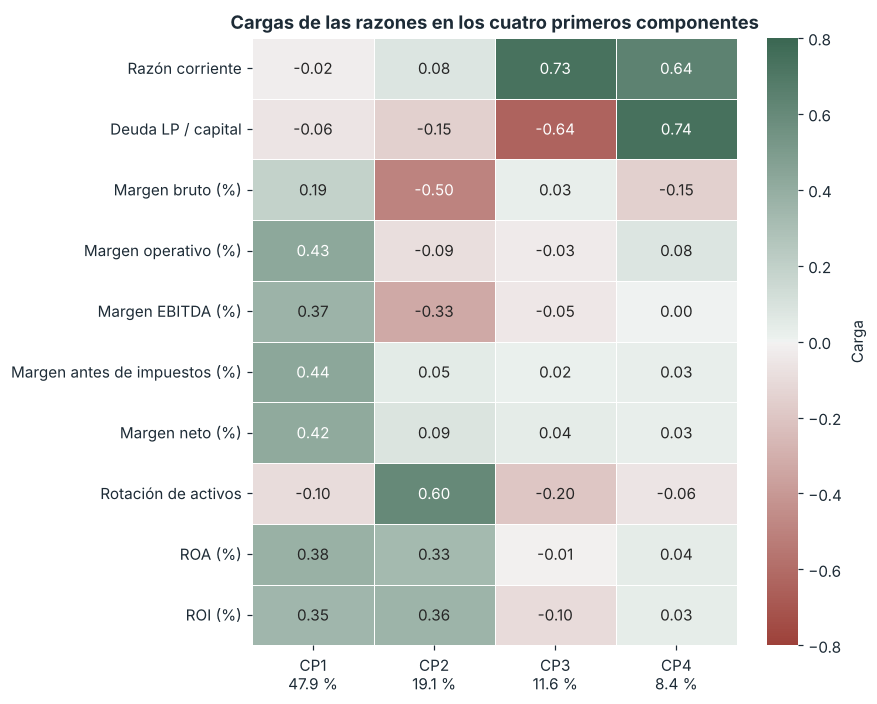

In [19]:
fig, ax = plt.subplots(figsize=(8, 6.5))
c4 = cargas.iloc[:, :4].copy(); c4.index = ETIQ
sns.heatmap(c4, annot=True, fmt=".2f", cmap=sns.diverging_palette(15, 150, s=60, l=40, as_cmap=True),
            center=0, vmin=-.8, vmax=.8, linewidths=.5, cbar_kws={"label": "Carga"}, ax=ax)
ax.set_title("Cargas de las razones en los cuatro primeros componentes")
ax.set_xticklabels([f"CP{i+1}\n{varianza['Varianza explicada (%)'].iloc[i]:.1f} %" for i in range(4)], rotation=0)
plt.tight_layout(); plt.show()

**CP1, rentabilidad (47,9 %).** Todas las cargas grandes son positivas y vienen de la rentabilidad: margen antes de impuestos (0,44), operativo (0,43), neto (0,42), ROA (0,38), EBITDA (0,37) y ROI (0,35). Liquidez y deuda casi no pesan (−0,02 y −0,06). Una empresa a la derecha de este eje gana más por cada dólar vendido y por cada dólar de activo.

**CP2, modelo de negocio: rotación frente a margen (19,1 %).** Sube con la rotación de activos (0,60), el ROI (0,36) y el ROA (0,33), y baja con el margen bruto (−0,50) y el margen EBITDA (−0,33). Arriba quedan las empresas que venden mucho en relación con sus activos y con márgenes estrechos (comercio, distribución); abajo, las intensivas en capital con márgenes amplios (servicios públicos, telecomunicaciones, salud). Es la identidad de DuPont: ROA = margen × rotación.

**CP3, solidez de balance (11,6 %).** Sube con la razón corriente (0,73) y baja con la deuda LP / capital (−0,64). Arriba están las empresas líquidas y poco endeudadas a largo plazo; abajo, las que tienen poca liquidez y mucha deuda. Es el eje que mira el comité cuando pregunta si la empresa puede atender una deuda adicional.

**CP4, no conservado (8,4 %).** Combina liquidez y deuda con el mismo signo (0,64 y 0,74): empresas que se financian a largo plazo y mantienen activos corrientes altos, típico de constructoras de vivienda con inventario. Es un rasgo sectorial más que una señal de capacidad de pago.

Ninguna razón es por sí sola un componente: cada eje existe porque varias conductas financieras se mueven juntas.

## 3.4 Las empresas en el plano de los dos primeros componentes

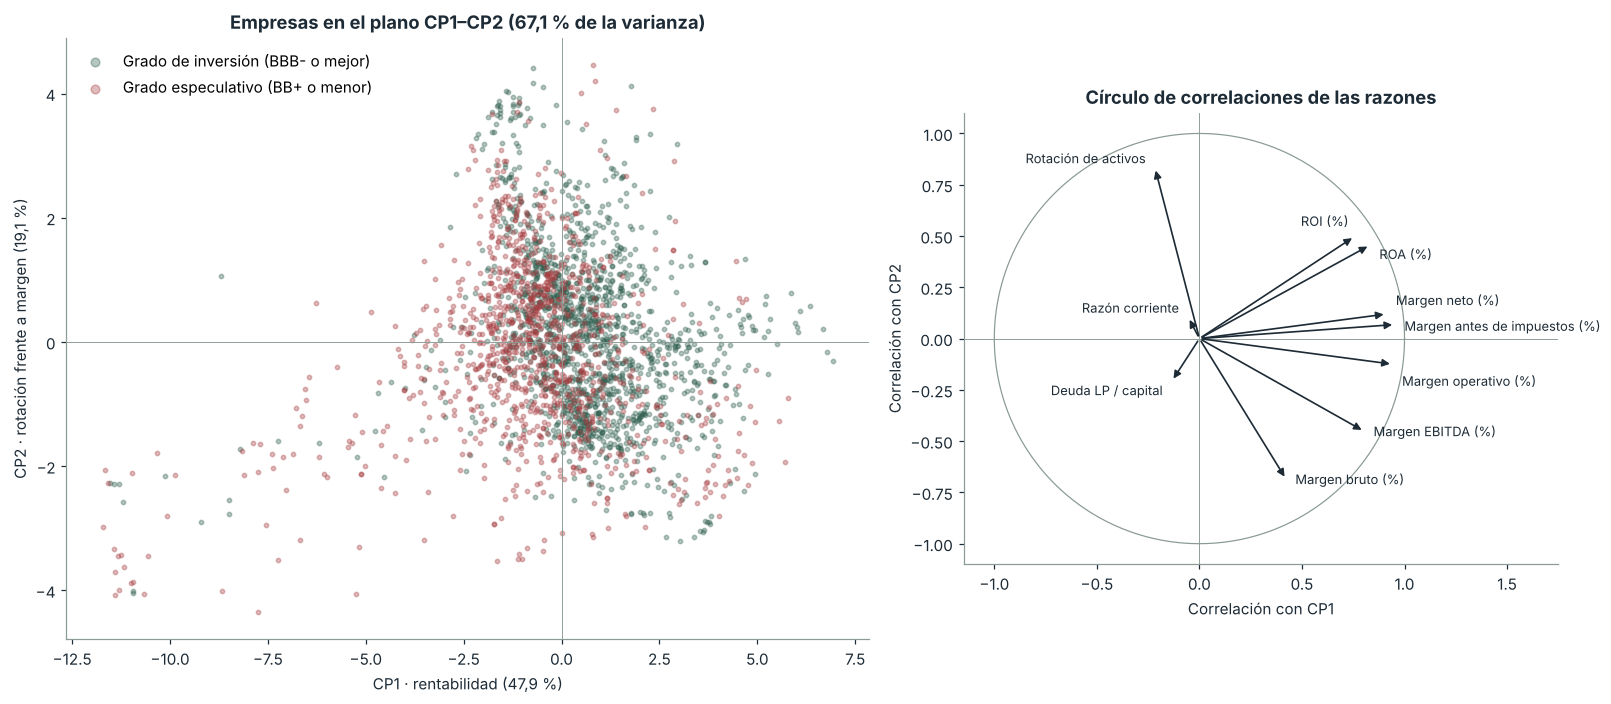

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})
gi = obs["Grado de inversión"].values == 1
ax[0].scatter(puntajes[gi, 0], puntajes[gi, 1], s=8, alpha=.35, color=VERDE, label="Grado de inversión (BBB- o mejor)")
ax[0].scatter(puntajes[~gi, 0], puntajes[~gi, 1], s=8, alpha=.35, color=VINO, label="Grado especulativo (BB+ o menor)")
ax[0].axhline(0, color=GRIS, lw=.6); ax[0].axvline(0, color=GRIS, lw=.6)
ax[0].set_xlabel(f"CP1 · rentabilidad ({pct(varianza.iloc[0, 1])} %)")
ax[0].set_ylabel(f"CP2 · rotación frente a margen ({pct(varianza.iloc[1, 1])} %)")
ax[0].set_title(f"Empresas en el plano CP1–CP2 ({pct(varianza.iloc[1, 2])} % de la varianza)")
ax[0].legend(frameon=False, loc="upper left", markerscale=2)

# Círculo de correlaciones: correlación de cada razón con CP1 y CP2
corr_cp = cargas[["CP1", "CP2"]] * np.sqrt(acp.explained_variance_[:2])
t = np.linspace(0, 2 * np.pi, 200)
ax[1].plot(np.cos(t), np.sin(t), color=GRIS, lw=.8)
desplaz = {"Net Profit Margin": (6, 9), "Pre-Tax Profit Margin": (6, -1), "Operating Margin": (6, -11),
           "ROA - Return On Assets": (6, -6), "ROI - Return On Investment": (-4, 10),
           "Current Ratio": (-6, 6), "Long-term Debt / Capital": (-6, -6), "Asset Turnover": (-6, 6)}
for v, e in zip(VARIABLES, ETIQ):
    x_, y_ = corr_cp.loc[v]
    ax[1].annotate("", xy=(x_, y_), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=TINTA, lw=1.1))
    dx, dy = desplaz.get(v, (6, 0))
    ax[1].annotate(e, (x_, y_), textcoords="offset points", xytext=(dx, dy), fontsize=8.5, color=TINTA,
                   ha="left" if dx >= 0 else "right", va="center")
ax[1].axhline(0, color=GRIS, lw=.6); ax[1].axvline(0, color=GRIS, lw=.6)
ax[1].set_xlim(-1.15, 1.75); ax[1].set_ylim(-1.1, 1.1); ax[1].set_aspect("equal")
ax[1].set_xlabel("Correlación con CP1"); ax[1].set_ylabel("Correlación con CP2")
ax[1].set_title("Círculo de correlaciones de las razones")
plt.tight_layout(); plt.show()

El plano resume el **67,1 %** de la variación de las diez razones; el resto está en los demás componentes. El círculo de la derecha muestra la correlación de cada razón con los dos ejes: los márgenes operativo, antes de impuestos y neto casi tocan el círculo sobre CP1 (correlación de 0,92 a 0,96), la rotación apunta hacia arriba y el margen bruto hacia abajo. Razón corriente y deuda quedan cerca del centro: este plano casi no las representa, y por eso se necesita el tercer componente.

El color es la calificación, que **no** participó en el ACP. Aun así, las empresas con grado de inversión se concentran a la derecha (más rentables) y las de grado especulativo dominan la cola izquierda, donde están las empresas con pérdidas. Hay mucha superposición en el centro: la rentabilidad explica parte de la calificación, no toda.

# 4. Segmentación mediante K-Means

## 4.1 Espacio de agrupamiento

K-Means se aplica sobre los **tres componentes conservados** (78,7 % de la varianza), no sobre las diez razones:

* En las razones originales, cinco márgenes muy correlacionados hacen que la rentabilidad cuente casi cinco veces en la distancia. En los componentes, cada dimensión entra una vez.
* Los componentes 4 a 10 recogen el 21 % restante, en buena parte ruido de razones redundantes.
* Tres dimensiones mantienen las distancias interpretables: alejarse en CP1 es ser más o menos rentable; en CP3, tener un balance más o menos sólido.

In [21]:
N_COMP = 3
S = puntajes[:, :N_COMP]

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(S)
    filas.append({"k": k, "Inercia": km.inertia_, "Silueta media": silhouette_score(S, km.labels_),
                  "Grupo más pequeño": np.bincount(km.labels_).min()})
evaluacion = pd.DataFrame(filas).set_index("k")
evaluacion["Caída de inercia (%)"] = -evaluacion["Inercia"].pct_change() * 100
evaluacion

,Inercia,Silueta media,Grupo más pequeño,Caída de inercia (%)
k,,,,
2,"14,867.18",0.28,1345,NaN
3,"10,639.74",0.31,84,28.43
4,"8,846.29",0.25,80,16.86
5,"7,497.78",0.26,69,15.24
6,"6,448.90",0.27,64,13.99
7,"5,879.09",0.26,61,8.84
8,"5,369.15",0.27,46,8.67
9,"4,961.01",0.26,46,7.60
10,"4,678.49",0.26,30,5.69


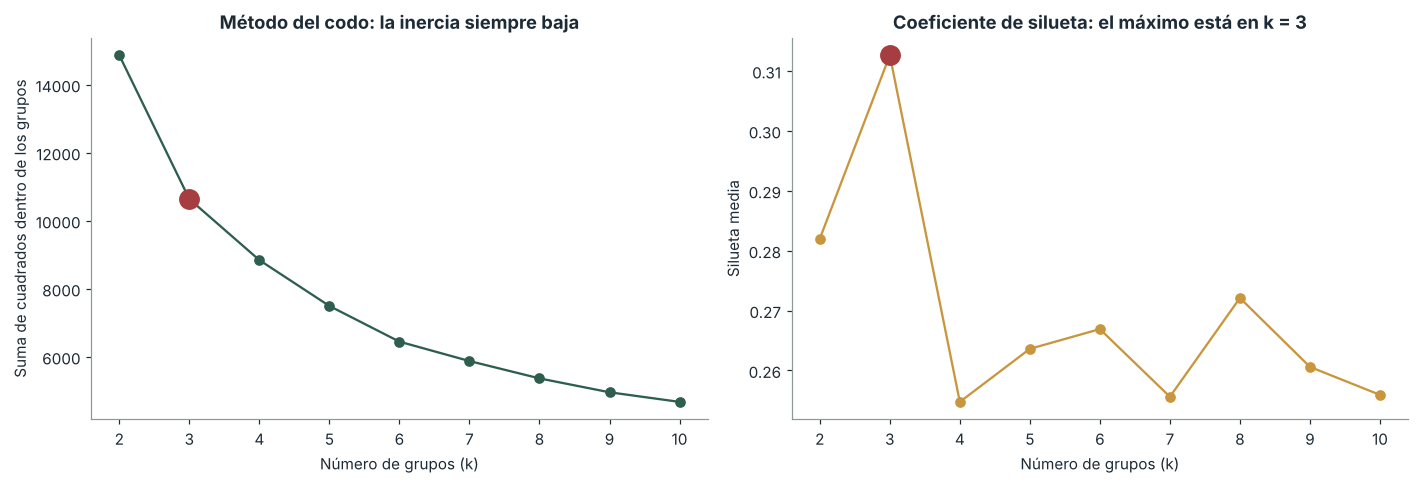

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(evaluacion.index, evaluacion["Inercia"], "-o", color=VERDE)
ax[0].scatter([3], [evaluacion.loc[3, "Inercia"]], s=160, color=VINO, zorder=3)
ax[0].set_title("Método del codo: la inercia siempre baja")
ax[0].set_xlabel("Número de grupos (k)"); ax[0].set_ylabel("Suma de cuadrados dentro de los grupos")
ax[1].plot(evaluacion.index, evaluacion["Silueta media"], "-o", color=OCRE)
ax[1].scatter([3], [evaluacion.loc[3, "Silueta media"]], s=160, color=VINO, zorder=3)
ax[1].set_title("Coeficiente de silueta: el máximo está en k = 3")
ax[1].set_xlabel("Número de grupos (k)"); ax[1].set_ylabel("Silueta media")
plt.tight_layout(); plt.show()

## 4.2 Elección de k

* **Codo.** La inercia cae 28,4 % al pasar de dos a tres grupos y luego 16,9 %, 15,2 %, 14,0 %… El codo no es nítido, pero el cambio de pendiente más fuerte ocurre en k = 3.
* **Silueta.** El máximo está en **k = 3 (0,313)**. Con k = 2 baja a 0,282 y con k = 4 a 0,255; de ahí en adelante oscila entre 0,25 y 0,28 sin volver a superar k = 3.
* **Lectura de negocio.** Con dos grupos, las empresas en pérdidas quedan mezcladas con las de margen estrecho y se pierde justo el grupo más riesgoso. Con tres, cada grupo tiene una lectura financiera clara (4.5).

**Decisión: k = 3.** Coinciden el máximo de silueta, el cambio de pendiente del codo y la interpretación. El tercer grupo es pequeño (84 empresas-periodo, 3 %), pero no es un artefacto: son las empresas con pérdidas operativas, y para una política de cupo son las que más importa separar.

Una silueta de 0,31 indica estructura débil a moderada: hay grupos, pero con fronteras anchas. Se discute en 4.4.

## 4.3 Estabilidad de la solución

K-Means depende del punto de partida. Se compara la solución final con otras diez semillas y con la que se obtendría usando cuatro componentes. El índice de Rand ajustado (ARI) vale 1 cuando dos particiones son idénticas.

In [23]:
km_final = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit(S)
etiquetas = km_final.labels_

ari_semillas = [adjusted_rand_score(etiquetas, KMeans(3, n_init=10, random_state=s).fit_predict(S)) for s in range(10)]
etiq_4 = KMeans(3, n_init=10, random_state=SEMILLA).fit_predict(puntajes[:, :4])
print("ARI frente a otras 10 semillas: mínimo", round(min(ari_semillas), 3), "| promedio", round(np.mean(ari_semillas), 3))
print("ARI frente a agrupar con 4 componentes:", round(adjusted_rand_score(etiquetas, etiq_4), 3))

ARI frente a otras 10 semillas: mínimo 0.979 | promedio 0.987
ARI frente a agrupar con 4 componentes: 0.98


La partición es estable: con cualquier semilla el ARI es de al menos 0,98, y usar cuatro componentes en vez de tres cambia muy pocas asignaciones. La decisión de 3.2 no altera los grupos.

## 4.4 Los grupos y su nombre

El número que K-Means le asigna a cada grupo (0, 1, 2) no tiene orden ni significado. Cada grupo se nombra por su perfil: se compara la media estandarizada del grupo con la de toda la base y se describe en palabras su margen, su rotación y, si se aparta mucho, su deuda o su liquidez. Un grupo cuyo margen operativo mediano es negativo se llama *en pérdidas operativas*.

In [24]:
MARGENES = ["Gross Margin", "Operating Margin", "EBITDA Margin", "Pre-Tax Profit Margin", "Net Profit Margin"]
Zdf = pd.DataFrame(Z, columns=VARIABLES).assign(g=etiquetas)
medias_z = Zdf.groupby("g").mean()

def nivel(z, alto, medio, bajo, corte=.25):
    return alto if z >= corte else (bajo if z <= -corte else medio)

nombres = {}
for g in medias_z.index:
    if obs.loc[etiquetas == g, "Operating Margin"].median() < 0:
        partes = ["En pérdidas operativas"]
    else:
        partes = [nivel(medias_z.loc[g, MARGENES + ["ROA - Return On Assets"]].mean(), "Margen alto", "Margen medio", "Margen estrecho"),
                  nivel(medias_z.loc[g, "Asset Turnover"], "rotación alta", "rotación media", "rotación baja")]
    if abs(medias_z.loc[g, "Long-term Debt / Capital"]) >= .5:
        partes.append("más apalancadas" if medias_z.loc[g, "Long-term Debt / Capital"] > 0 else "menos apalancadas")
    if abs(medias_z.loc[g, "Current Ratio"]) >= .5:
        partes.append("más líquidas" if medias_z.loc[g, "Current Ratio"] > 0 else "menos líquidas")
    nombres[g] = ", ".join(partes)

obs["Segmento"] = [nombres[g] for g in etiquetas]
silueta = silhouette_samples(S, etiquetas)
obs["Silueta"] = silueta
obs[["CP1", "CP2", "CP3"]] = S

# Colores por rentabilidad del centro (CP1): no por el rating
orden_seg = [nombres[g] for g in np.argsort(-km_final.cluster_centers_[:, 0])]
COLOR = dict(zip(orden_seg, [VERDE, OCRE, VINO]))

resumen = obs.groupby("Segmento").agg(**{"Empresas-periodo": ("Silueta", "size"), "Silueta media": ("Silueta", "mean")})
resumen["Participación (%)"] = resumen["Empresas-periodo"] / len(obs) * 100
centros = pd.DataFrame(km_final.cluster_centers_, columns=["CP1", "CP2", "CP3"], index=[nombres[g] for g in range(3)])
resumen.join(centros).loc[orden_seg]

,Empresas-periodo,Silueta media,Participación (%),CP1,CP2,CP3
Segmento,,,,,,
"Margen alto, rotación baja",1053,0.29,39.09,1.73,-0.76,0.01
"Margen estrecho, rotación alta",1557,0.32,57.80,-0.76,0.63,-0.04
En pérdidas operativas,84,0.43,3.12,-7.61,-2.19,0.52


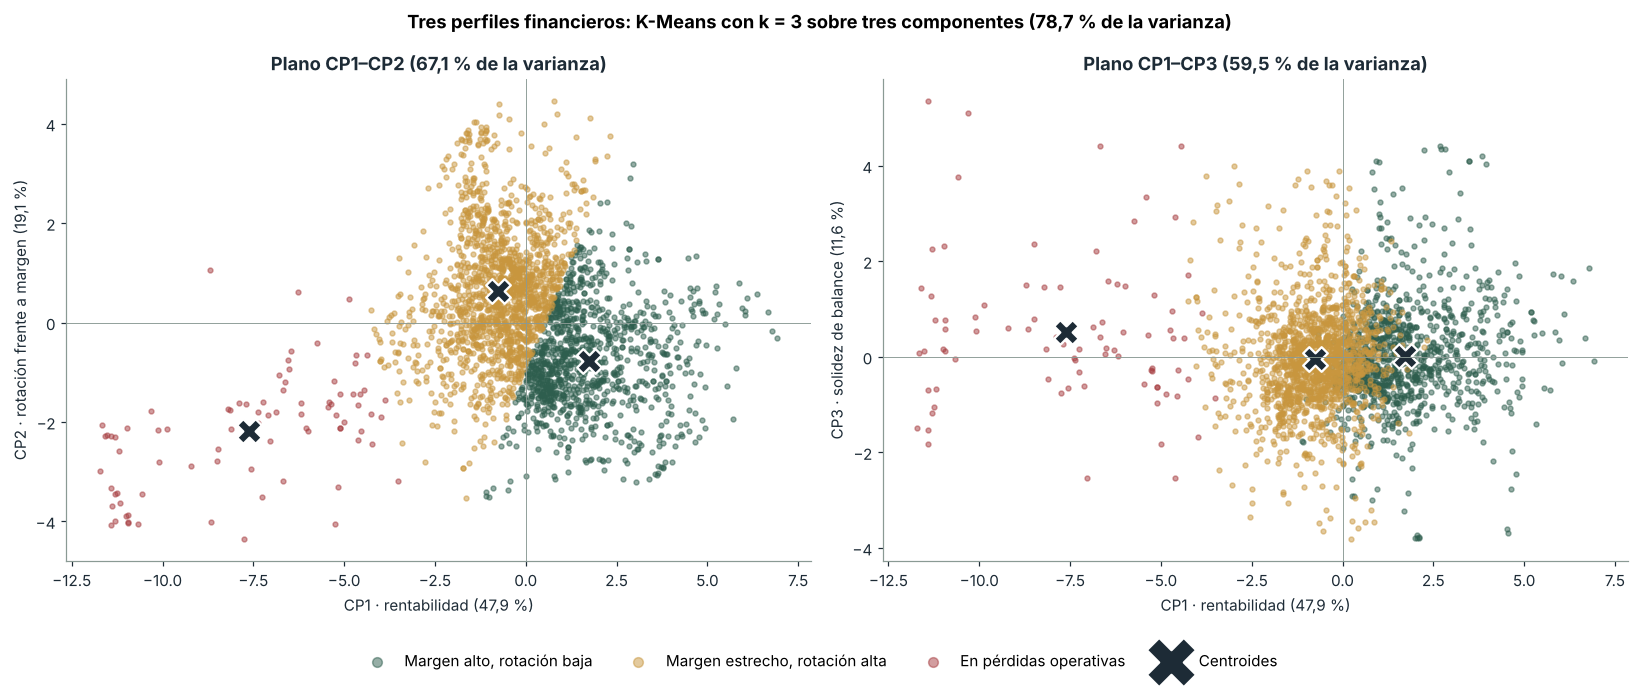

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for seg in orden_seg:
    m = obs["Segmento"] == seg
    ax[0].scatter(obs.loc[m, "CP1"], obs.loc[m, "CP2"], s=10, alpha=.5, color=COLOR[seg], label=seg)
    ax[1].scatter(obs.loc[m, "CP1"], obs.loc[m, "CP3"], s=10, alpha=.5, color=COLOR[seg], label=seg)
for a, j, lab in [(ax[0], 1, f"CP2 · rotación frente a margen ({pct(varianza.iloc[1, 1])} %)"),
                  (ax[1], 2, f"CP3 · solidez de balance ({pct(varianza.iloc[2, 1])} %)")]:
    a.scatter(centros["CP1"], centros.iloc[:, j], marker="X", s=260, color=TINTA, edgecolor="white", lw=1.5, label="Centroides")
    a.set_xlabel(f"CP1 · rentabilidad ({pct(varianza.iloc[0, 1])} %)"); a.set_ylabel(lab)
    a.axhline(0, color=GRIS, lw=.6); a.axvline(0, color=GRIS, lw=.6)
ax[0].set_title(f"Plano CP1–CP2 ({pct(varianza.iloc[1, 2])} % de la varianza)")
ax[1].set_title(f"Plano CP1–CP3 ({pct(varianza.iloc[0, 1] + varianza.iloc[2, 1])} % de la varianza)")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.04), markerscale=2)
plt.suptitle(f"Tres perfiles financieros: K-Means con k = 3 sobre tres componentes ({pct(varianza.iloc[2, 2])} % de la varianza)", fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

En el plano CP1–CP2 los grupos se ordenan sobre todo de izquierda a derecha: rentabilidad. *En pérdidas operativas* ocupa la cola izquierda, lejos de los demás. Entre *margen alto, rotación baja* y *margen estrecho, rotación alta* la frontera es diagonal: separa a las empresas más rentables y de márgenes amplios (abajo a la derecha) de las de márgenes estrechos y alta rotación (arriba al centro).

En el plano CP1–CP3 se ve otra cosa importante: **los tres grupos ocupan todo el rango del eje de solidez de balance**. Los centros de los dos grupos grandes están en cero sobre CP3 y el del grupo en pérdidas apenas por encima (0,52). La deuda y la liquidez no forman grupos por sí solas; varían dentro de cada perfil (se retoma en 4.8).

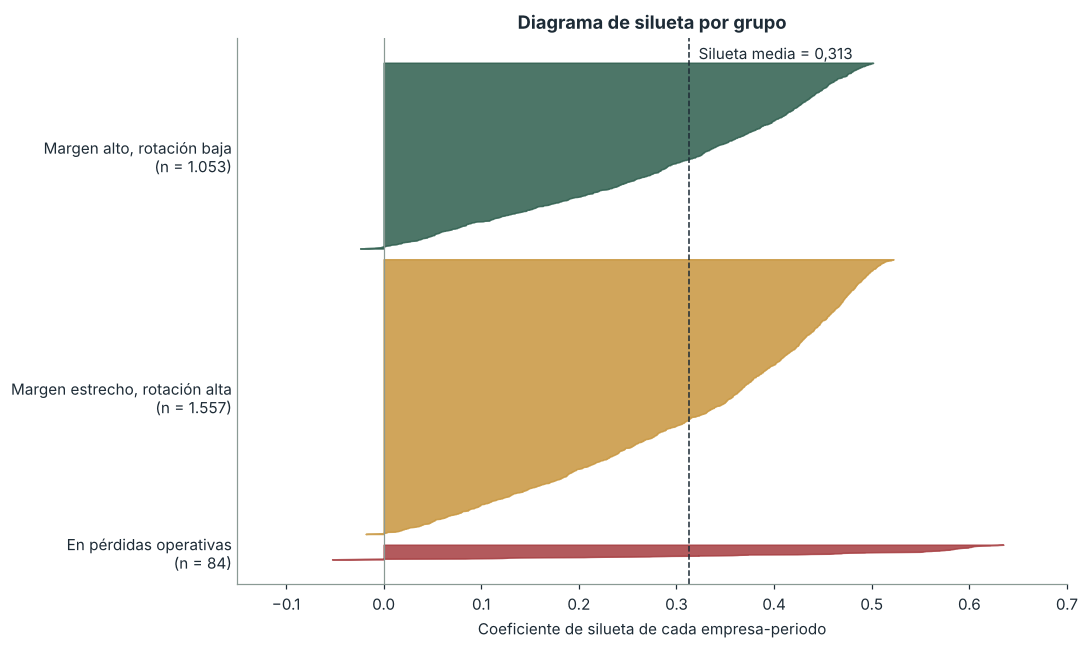

Silueta negativa (quedaría mejor en otro grupo): 0.9%
Silueta menor a 0,1 (en la frontera): 12.2%


,mean,25%,50%,75%
Segmento,,,,
"Margen alto, rotación baja",0.29,0.18,0.32,0.42
"Margen estrecho, rotación alta",0.32,0.21,0.36,0.44
En pérdidas operativas,0.43,0.32,0.52,0.59


In [26]:
fig, ax = plt.subplots(figsize=(10, 6))
y0, centros_y, etiquetas_y = 10, [], []
for seg in orden_seg[::-1]:
    v = np.sort(obs.loc[obs["Segmento"] == seg, "Silueta"].values)
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLOR[seg], alpha=.85)
    centros_y.append(y0 + len(v) / 2)
    etiquetas_y.append(f"{seg}\n(n = {len(v):,})".replace("n = 1,", "n = 1."))
    y0 += len(v) + 60
ax.set_yticks(centros_y); ax.set_yticklabels(etiquetas_y); ax.tick_params(axis="y", length=0)
ax.axvline(silueta.mean(), color=TINTA, ls="--", lw=1)
ax.text(silueta.mean() + .01, y0 - 40, f"Silueta media = {pct(silueta.mean(), 3)}", color=TINTA)
ax.axvline(0, color=GRIS, lw=.8)
ax.set_xlabel("Coeficiente de silueta de cada empresa-periodo"); ax.set_xlim(-.15, .7)
ax.set_title("Diagrama de silueta por grupo")
plt.tight_layout(); plt.show()

print(f"Silueta negativa (quedaría mejor en otro grupo): {(silueta < 0).mean():.1%}")
print(f"Silueta menor a 0,1 (en la frontera): {(silueta < .1).mean():.1%}")
obs.groupby("Segmento")["Silueta"].describe()[["mean", "25%", "50%", "75%"]].loc[orden_seg]

**Qué tan nítidos son los grupos.** La silueta media es 0,31: hay estructura, pero no compartimentos cerrados.

* *En pérdidas operativas* es el grupo más cohesionado (silueta media 0,43): sus empresas están claramente lejos de las demás.
* Los otros dos tienen siluetas de 0,29 y 0,32 y comparten una frontera ancha.
* Solo el 0,9 % de las empresas tiene silueta negativa (estaría mejor en otro grupo), pero el **12,2 % está por debajo de 0,1**: son empresas de frontera. Para ellas, la etiqueta del grupo es una referencia débil y el análisis individual pesa más.

## 4.5 Perfil de cada grupo con las variables originales

Los grupos se describen con las **medianas** de las razones originales (sin winsorizar ni estandarizar), porque las medianas no se dejan arrastrar por las colas.

In [27]:
perfil = obs.groupby("Segmento")[VARIABLES].median().T.loc[:, orden_seg]
perfil.index = ETIQ
perfil.loc["Empresas-periodo"] = obs["Segmento"].value_counts()[orden_seg]
perfil.loc["Rotación × margen neto (ROA aprox.)"] = perfil.loc["Rotación de activos"] * perfil.loc["Margen neto (%)"]
perfil

Segmento,"Margen alto, rotación baja","Margen estrecho, rotación alta",En pérdidas operativas
Razón corriente,1.34,1.68,1.70
Deuda LP / capital,0.43,0.42,0.46
Margen bruto (%),60.96,25.58,43.00
Margen operativo (%),21.09,7.55,-32.65
Margen EBITDA (%),32.23,12.49,-16.34
Margen antes de impuestos (%),17.74,5.44,-40.83
Margen neto (%),13.10,3.78,-36.96
Rotación de activos,0.43,0.95,0.39
ROA (%),6.17,4.00,-17.65
ROI (%),8.91,6.17,-26.78


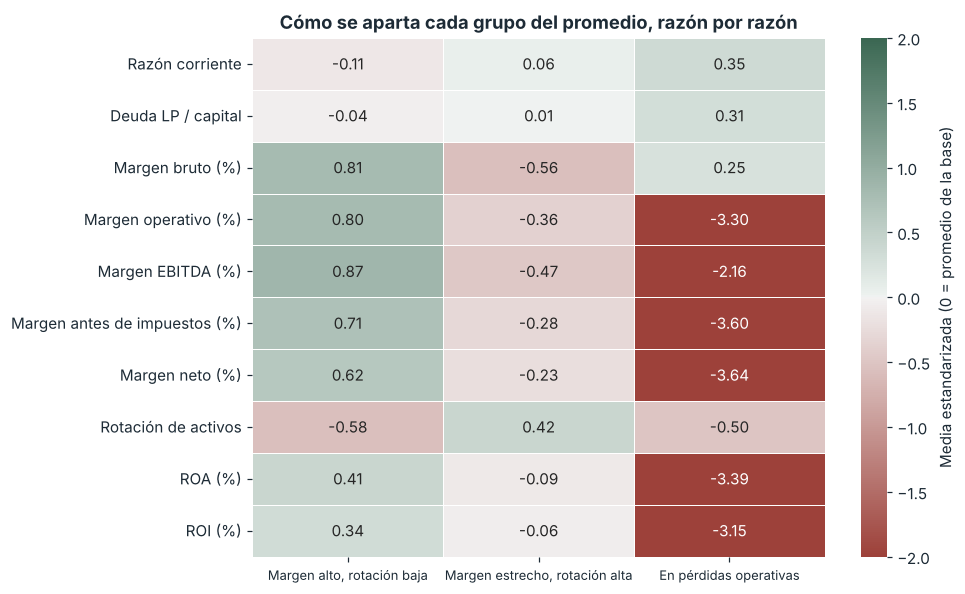

In [28]:
fig, ax = plt.subplots(figsize=(9, 5.5))
mz = medias_z.copy(); mz.index = [nombres[g] for g in mz.index]; mz = mz.loc[orden_seg]; mz.columns = ETIQ
sns.heatmap(mz.T, annot=True, fmt=".2f", cmap=sns.diverging_palette(15, 150, s=60, l=40, as_cmap=True),
            center=0, vmin=-2, vmax=2, linewidths=.5, cbar_kws={"label": "Media estandarizada (0 = promedio de la base)"}, ax=ax)
ax.set_title("Cómo se aparta cada grupo del promedio, razón por razón")
ax.set_xlabel(""); plt.xticks(rotation=0, fontsize=8.5)
plt.tight_layout(); plt.show()

**Margen alto, rotación baja (1.053 empresas-periodo, 39 %).** Margen bruto mediano de 61 %, margen operativo de 21 % y neto de 13 %. Venden poco en relación con sus activos (rotación 0,43 veces) pero cada venta deja mucho: ROA de 6,2 % y ROI de 8,9 %. Tienen la razón corriente más baja (1,34), algo normal en negocios con ingresos estables como servicios públicos, telecomunicaciones o software, que no necesitan mucho capital de trabajo.

**Margen estrecho, rotación alta (1.557, 58 %).** Margen bruto de 26 %, operativo de 7,6 % y neto de 3,8%; compensan con una rotación de 0,95 veces, más del doble que el grupo anterior. Por eso su ROA (4,0 %) y su ROI (6,2 %) no quedan tan atrás. Es el perfil de comercio, manufactura y distribución: ganan por volumen. Son más líquidas (1,68).

**En pérdidas operativas (84, 3 %).** Margen operativo de −33 %, neto de −37 %, ROA de −18 % y ROI de −27 %. Su margen bruto (43 %) no es malo: el problema está debajo, en gastos operativos y financieros que la venta no alcanza a cubrir. Su liquidez (1,70) es similar a la del grupo de margen estrecho, lo que muestra que en este grupo la liquidez no compensa la falta de rentabilidad.

**Lo que no separa a los grupos: la deuda.** La deuda LP / capital mediana es 0,43, 0,42 y 0,46. Los tres perfiles se endeudan en proporciones parecidas; lo que los distingue es cómo generan utilidades.

## 4.6 Validación externa: ¿los grupos ordenan la calificación?

La calificación no entró al modelo. Ahora se cruza con los grupos.

In [29]:
validacion = obs.groupby("Segmento").agg(**{
    "Empresas-periodo": ("Puntaje", "size"),
    "Grado de inversión (%)": ("Grado de inversión", lambda s: s.mean() * 100),
    "Puntaje mediano": ("Puntaje", "median"),
}).loc[orden_seg]
validacion["Rating mediano"] = validacion["Puntaje mediano"].apply(lambda p: PUNTAJE_A_RATING[int(round(p))])
validacion

,Empresas-periodo,Grado de inversión (%),Puntaje mediano,Rating mediano
Segmento,,,,
"Margen alto, rotación baja",1053,73.41,8.00,BBB+
"Margen estrecho, rotación alta",1557,48.23,11.00,BB+
En pérdidas operativas,84,22.62,14.00,B+


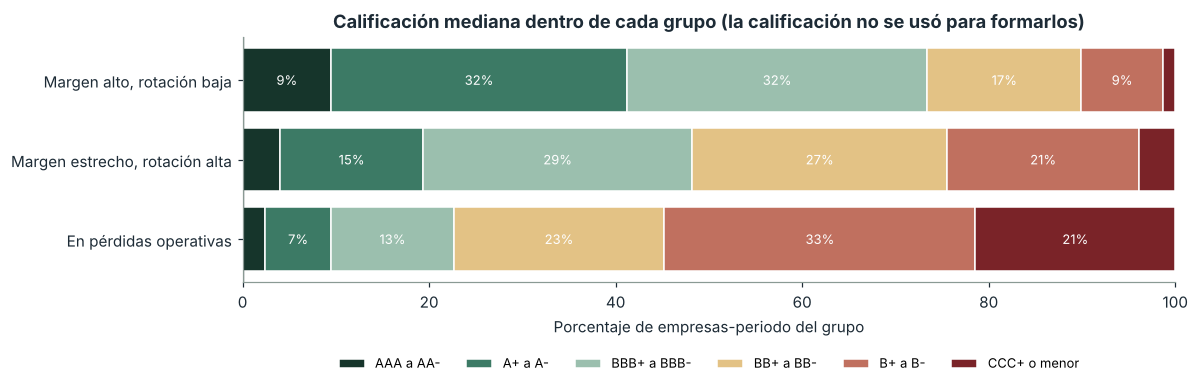

In [30]:
def familia_rating(p):
    if p <= 4: return "AAA a AA-"
    if p <= 7: return "A+ a A-"
    if p <= 10: return "BBB+ a BBB-"
    if p <= 13: return "BB+ a BB-"
    if p <= 16: return "B+ a B-"
    return "CCC+ o menor"
FAM = ["AAA a AA-", "A+ a A-", "BBB+ a BBB-", "BB+ a BB-", "B+ a B-", "CCC+ o menor"]
COL_FAM = ["#16352B", "#3C7A65", "#9BBFAE", "#E3C285", "#C0705F", "#7A2328"]
tab = pd.crosstab(obs["Segmento"], obs["Puntaje"].apply(familia_rating), normalize="index").reindex(columns=FAM).fillna(0).loc[orden_seg[::-1]] * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
izq = np.zeros(len(tab))
for f, c in zip(FAM, COL_FAM):
    ax.barh(tab.index, tab[f], left=izq, color=c, label=f, edgecolor="white")
    for i, (l, v) in enumerate(zip(izq, tab[f])):
        if v >= 6: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8.5)
    izq += tab[f].values
ax.axvline(0, color=TINTA)
ax.set_xlabel("Porcentaje de empresas-periodo del grupo"); ax.set_xlim(0, 100)
ax.set_title("Calificación mediana dentro de cada grupo (la calificación no se usó para formarlos)")
ax.legend(ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.25), loc="upper center", fontsize=8.5)
plt.tight_layout(); plt.show()

Los grupos, formados solo con razones financieras, **ordenan la calificación de las agencias**:

* *Margen alto, rotación baja:* rating mediano **BBB+**, 73,4 % con grado de inversión.
* *Margen estrecho, rotación alta:* rating mediano **BB+**, 48,2 % con grado de inversión.
* *En pérdidas operativas:* rating mediano **B+**, 22,6 % con grado de inversión.

Entre el primer y el tercer grupo hay seis escalones de calificación. Esto valida que los perfiles capturan algo de la capacidad de pago. También muestra el límite: cada grupo contiene calificaciones de todo el rango, porque las agencias miran tamaño, sector, posición competitiva y gobierno corporativo, que no están en estas razones.

## 4.7 Composición sectorial

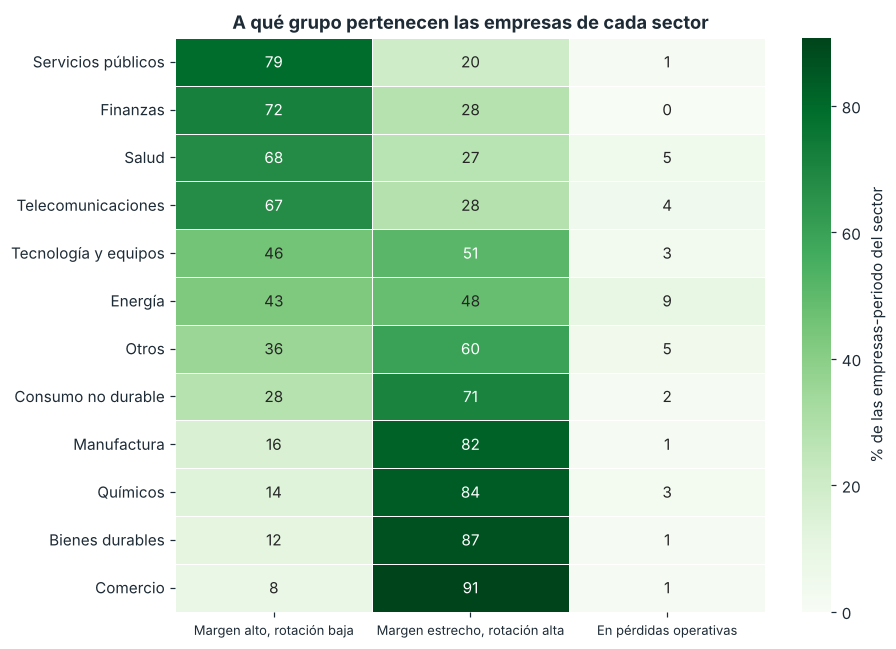

In [31]:
SECTORES = {"BusEq": "Tecnología y equipos", "Chems": "Químicos", "Durbl": "Bienes durables", "Enrgy": "Energía",
            "Hlth": "Salud", "Manuf": "Manufactura", "Money": "Finanzas", "NoDur": "Consumo no durable",
            "Other": "Otros", "Shops": "Comercio", "Telcm": "Telecomunicaciones", "Utils": "Servicios públicos"}
sec = pd.crosstab(obs["Sector"].map(SECTORES), obs["Segmento"], normalize="index")[orden_seg] * 100
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(sec.sort_values(orden_seg[0], ascending=False), annot=True, fmt=".0f", cmap="Greens", linewidths=.5,
            cbar_kws={"label": "% de las empresas-periodo del sector"}, ax=ax)
ax.set_title("A qué grupo pertenecen las empresas de cada sector"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=0, fontsize=8.5); plt.tight_layout(); plt.show()

Los sectores confirman la lectura del eje de modelo de negocio. Servicios públicos (79 %), finanzas (72 %), salud (68 %) y telecomunicaciones (67 %) caen mayoritariamente en *margen alto, rotación baja*. Comercio (91 %), bienes durables (87 %), químicos (84 %) y manufactura (82 %) caen en *margen estrecho, rotación alta*. Energía tiene la mayor proporción de empresas en pérdidas operativas (9 %), coherente con la caída del precio del petróleo entre 2014 y 2016. Ningún sector cae completo en un grupo: el perfil financiero no es solo el sector.

## 4.8 De los grupos a una lectura de cupo

La pregunta del taller es qué capacidad de cupo tiene una empresa según sus razones. Se propone una lectura en dos pasos:

**Paso 1: el perfil fija la postura de partida.** Se usa la proporción de empresas con grado de inversión de cada grupo, dividida en tercios. Es una regla ilustrativa y explícita, no un estándar regulatorio:

| Grado de inversión en el grupo | Postura de cupo | Qué implica |
|---|---|---|
| Dos tercios o más | Cupo amplio | Cupo estándar o ampliable, revisión anual |
| Entre un tercio y dos tercios | Cupo condicionado | Cupo sujeto a covenants de apalancamiento, revisión semestral |
| Menos de un tercio | Cupo restringido | Cupo bajo, con garantías y seguimiento trimestral |

**Paso 2: el balance afina dentro del grupo.** Como la deuda y la liquidez no separan a los grupos (4.4), se revisa la posición de la empresa en el eje de solidez de balance (CP3) frente a las demás de su grupo, dividida en tercios.

In [32]:
def postura(pct):
    return "Cupo amplio" if pct >= 200 / 3 else ("Cupo condicionado" if pct >= 100 / 3 else "Cupo restringido")

lectura = validacion[["Empresas-periodo", "Grado de inversión (%)", "Rating mediano"]].copy()
lectura["Postura de cupo"] = lectura["Grado de inversión (%)"].apply(postura)

obs["Balance dentro del grupo"] = obs.groupby("Segmento")["CP3"].transform(
    lambda s: pd.qcut(s, 3, labels=["Tercio más débil", "Tercio medio", "Tercio más sólido"]))
ajuste = obs.pivot_table(index="Segmento", columns="Balance dentro del grupo", values="Grado de inversión",
                         aggfunc="mean", observed=True).loc[orden_seg] * 100
lectura.join(ajuste.round(1).add_prefix("Grado inv. % · "))

,Empresas-periodo,Grado de inversión (%),Rating mediano,Postura de cupo,Grado inv. % · Tercio más débil,Grado inv. % · Tercio medio,Grado inv. % · Tercio más sólido
Segmento,,,,,,,
"Margen alto, rotación baja",1053,73.41,BBB+,Cupo amplio,67.20,75.50,77.50
"Margen estrecho, rotación alta",1557,48.23,BB+,Cupo condicionado,38.00,55.70,51.10
En pérdidas operativas,84,22.62,B+,Cupo restringido,7.10,25.00,35.70


La solidez de balance sí discrimina **dentro** de cada perfil, sobre todo en el tercio más débil:

* En *margen alto, rotación baja*, el grado de inversión pasa de 67 % en el tercio con peor balance a 77 % en el mejor.
* En *margen estrecho, rotación alta*, de 38 % a 51–56 %.
* En *en pérdidas operativas*, de 7 % a 36 %: una empresa con pérdidas pero líquida y poco endeudada tiene cinco veces más probabilidad de ser grado de inversión que una con pérdidas y balance débil.

La lectura de cupo queda así: **el perfil de rentabilidad fija la postura y el balance ordena, dentro de cada grupo, a quién revisar primero.** Si se aplica la misma regla de tercios a cada casilla de la tabla, la postura casi no cambia; lo que cambia es la distancia al escalón de abajo. Una empresa de margen estrecho con el balance más débil (38 % de grado de inversión) está más cerca del límite del cupo restringido que una de su mismo grupo con balance medio (56 %). Y una empresa en pérdidas con el balance más sólido (36 %) se parece más a las de margen estrecho y balance débil que al resto de su grupo.

## 4.9 Ubicar una empresa nueva

Con el escalador, el ACP y los centros ya ajustados, una empresa que no estaba en la base se puede ubicar: se le aplican los mismos recortes, la misma estandarización y la misma proyección, y se busca el centro más cercano. Es lo que hace el simulador de la aplicación.

In [33]:
def ubicar(valores):
    x = pd.DataFrame([valores])[VARIABLES].astype(float).clip(inf, sup, axis=1)
    s = acp.transform(escalador.transform(x))[:, :N_COMP] * signos[:N_COMP]
    d = np.linalg.norm(km_final.cluster_centers_ - s, axis=1)
    o = np.argsort(d)
    margen = (d[o[1]] - d[o[0]]) / d[o[1]]
    seg = nombres[o[0]]
    return {"Segmento": seg, "Postura": lectura.loc[seg, "Postura de cupo"],
            "CP1": round(s[0, 0], 2), "CP2": round(s[0, 1], 2), "CP3": round(s[0, 2], 2),
            "Margen frente al segundo centro": f"{margen:.0%}", "Segundo más cercano": nombres[o[1]]}

ejemplos = {
    "Distribuidora (margen 4 %, rotación 2,1)": {"Current Ratio": 1.4, "Long-term Debt / Capital": .45, "Gross Margin": 18,
        "Operating Margin": 5, "EBITDA Margin": 7, "Pre-Tax Profit Margin": 4.2, "Net Profit Margin": 3.1,
        "Asset Turnover": 2.1, "ROA - Return On Assets": 6.5, "ROI - Return On Investment": 9},
    "Empresa de servicios públicos (margen 22 %)": {"Current Ratio": .9, "Long-term Debt / Capital": .52, "Gross Margin": 65,
        "Operating Margin": 22, "EBITDA Margin": 35, "Pre-Tax Profit Margin": 16, "Net Profit Margin": 11,
        "Asset Turnover": .3, "ROA - Return On Assets": 3.4, "ROI - Return On Investment": 5.5},
    "Empresa con pérdidas y deuda alta": {"Current Ratio": .8, "Long-term Debt / Capital": .85, "Gross Margin": 30,
        "Operating Margin": -25, "EBITDA Margin": -10, "Pre-Tax Profit Margin": -32, "Net Profit Margin": -30,
        "Asset Turnover": .5, "ROA - Return On Assets": -14, "ROI - Return On Investment": -20},
}
pd.DataFrame({k: ubicar(v) for k, v in ejemplos.items()}).T

,Segmento,Postura,CP1,CP2,CP3,Margen frente al segundo centro,Segundo más cercano
"Distribuidora (margen 4 %, rotación 2,1)","Margen estrecho, rotación alta",Cupo condicionado,-0.97,2.04,-0.68,60%,"Margen alto, rotación baja"
Empresa de servicios públicos (margen 22 %),"Margen alto, rotación baja",Cupo amplio,1.11,-1.54,-0.59,60%,"Margen estrecho, rotación alta"
Empresa con pérdidas y deuda alta,En pérdidas operativas,Cupo restringido,-6.22,-1.79,-1.24,63%,"Margen estrecho, rotación alta"


Las tres empresas hipotéticas caen donde su perfil lo anticipa. La columna *margen frente al segundo centro* indica qué tan clara es la asignación: cuanto más cerca de 0 %, más cerca está la empresa de la frontera con el segundo grupo y más conviene un análisis individual.

# 5. Sensibilidad de las decisiones

Tres decisiones de preparación pueden cambiar el resultado. Se repite el análisis cambiando una a la vez.

In [34]:
def correr(Xm, normalizar=False, q=.01, n_comp=None, k=3):
    a, b = Xm.quantile(q), Xm.quantile(1 - q)
    Zm = StandardScaler().fit_transform(Xm.clip(a, b, axis=1))
    if normalizar:
        Zm = normalize(Zm)
    p = PCA().fit(Zm)
    nc = n_comp or int((p.explained_variance_ > p.explained_variance_.mean()).sum())
    Sm = p.transform(Zm)[:, :nc]
    ev = {kk: silhouette_score(Sm, KMeans(kk, n_init=10, random_state=SEMILLA).fit_predict(Sm)) for kk in range(2, 7)}
    lab = KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(Sm)
    val = (obs.assign(g=lab).groupby("g").agg(n=("Puntaje", "size"), gi=("Grado de inversión", "mean"), r=("Puntaje", "median"))
              .sort_values("r"))
    return {"Componentes": nc, "Var. conservada (%)": round(p.explained_variance_ratio_[:nc].sum() * 100, 1),
            "k con mejor silueta": max(ev, key=ev.get), "Silueta k=3": round(ev[3], 3),
            "Tamaños (k=3)": list(val["n"]), "Rating mediano (k=3)": [PUNTAJE_A_RATING[int(round(r))] for r in val["r"]],
            "ARI vs. solución final": round(adjusted_rand_score(etiquetas, lab), 3)}

sens = pd.DataFrame({
    "Solución final (winsor 1 %, sin normalizar filas)": correr(X),
    "Normalizar filas a longitud 1 (como en clase)": correr(X, normalizar=True),
    "Sin winsorizar": correr(X, q=0.0),
    "Winsorizar al 5 %": correr(X, q=.05),
}).T
sens

,Componentes,Var. conservada (%),k con mejor silueta,Silueta k=3,Tamaños (k=3),Rating mediano (k=3),ARI vs. solución final
"Solución final (winsor 1 %, sin normalizar filas)",3,78.70,3,0.31,"[1053, 1557, 84]","[BBB+, BB+, B+]",1.00
Normalizar filas a longitud 1 (como en clase),4,83.70,2,0.30,"[1088, 830, 776]","[BBB+, BBB, BB-]",0.50
Sin winsorizar,4,85.60,2,0.33,"[1350, 1324, 20]","[BBB, BB+, B]",0.56
Winsorizar al 5 %,3,81.20,2,0.28,"[896, 1003, 795]","[BBB+, BBB, BB]",0.49


In [35]:
etiq_k4 = KMeans(4, n_init=10, random_state=SEMILLA).fit_predict(S)
nombres_k4 = obs.assign(g=etiq_k4).groupby("g").agg(r=("Puntaje", "median"), gi=("Grado de inversión", "mean"),
                                                    m=("Operating Margin", "median"), t=("Asset Turnover", "median"))
nombres_k4["Rating mediano"] = nombres_k4["r"].apply(lambda p: PUNTAJE_A_RATING[int(round(p))])
nombres_k4 = nombres_k4.rename(columns={"r": "Puntaje mediano", "gi": "Grado de inversión", "m": "Margen operativo mediano",
                                        "t": "Rotación mediana"})
print("Perfil de los cuatro grupos con k = 4:")
display(nombres_k4)
print("Cómo se reparten en ellos los tres grupos finales:")
display(pd.crosstab(obs["Segmento"], etiq_k4, colnames=["Grupo con k = 4"]).loc[orden_seg])

Perfil de los cuatro grupos con k = 4:


,Puntaje mediano,Grado de inversión,Margen operativo mediano,Rotación mediana,Rating mediano
g,,,,,
0,8.00,0.77,25.17,0.43,BBB+
1,9.50,0.59,8.20,1.23,BBB-
2,11.00,0.43,9.87,0.53,BB+
3,14.00,0.23,-33.78,0.39,B+


Cómo se reparten en ellos los tres grupos finales:


Grupo con k = 4,0,1,2,3
Segmento,,,,
"Margen alto, rotación baja",710,68,275,0
"Margen estrecho, rotación alta",0,901,656,0
En pérdidas operativas,0,0,4,80


* **Normalizar las filas, como en clase.** Cambia el resultado de fondo (ARI 0,50). El grupo en pérdidas desaparece y los grupos se vuelven de *estilo* financiero, porque la normalización borra la magnitud: una empresa con −37 % de margen y otra con −2 % quedan en la misma dirección. Para una pregunta de cupo, donde el nivel importa, esa transformación no es la adecuada.
* **Sin winsorizar.** K-Means dedica un grupo a una veintena de empresas extremas y deja el resto en dos bloques (ARI 0,56). La winsorización es la que permite que los grupos describan a la mayoría.
* **Winsorizar al 5 %.** Al recortar más, las empresas en pérdidas se acercan al resto y el grupo de riesgo se convierte en uno de casi 800 empresas de baja rentabilidad (rating mediano BB); la mejor silueta pasa a k = 2. El 1 % es el estándar en finanzas y conserva mejor la cola de riesgo.
* **k = 4.** El cuarto grupo sale de reorganizar los dos grupos grandes: queda un núcleo de margen alto (rating mediano BBB+) y aparecen un grupo de margen medio con rotación alta (BBB-) y otro de margen medio con rotación baja (BB+). El grupo en pérdidas se mantiene casi intacto. Es una lectura más fina, y la calificación también la ordena, pero con menor silueta (0,255).

La conclusión central (un grupo rentable de margen alto, uno de margen estrecho y alta rotación, y uno en pérdidas, ordenados por calificación) se mantiene mientras se trabaje con niveles y se controlen las colas.

# 6. Verificación con el módulo de la aplicación

La aplicación de Streamlit no usa capturas ni resultados guardados: llama a las funciones de `analisis.py`, que hacen los mismos pasos de este notebook. La celda siguiente comprueba que los resultados son idénticos.

In [36]:
import analisis as A

df_m, _ = A.cargar_datos(RUTA)
obs_m = A.construir_observaciones(df_m)
prep_m = A.preparar_matriz(obs_m, A.VARIABLES_MODELO, q=0.01)
acp_m = A.orientar_componentes(A.ajustar_acp(prep_m.Z, prep_m.variables))
km_m = A.ajustar_kmeans(acp_m["puntajes"][:, :3], k=3, semilla=42)

print("Mismas observaciones:", len(obs_m) == len(obs))
print("Misma varianza explicada:", np.allclose(acp_m["varianza"]["Varianza explicada (%)"].values, varianza["Varianza explicada (%)"].values))
print("Misma partición (ARI):", adjusted_rand_score(etiquetas, km_m["etiquetas"]))
print("Misma silueta media:", round(km_m["silueta_media"], 4), "=", round(silueta.mean(), 4))

Mismas observaciones: True
Misma varianza explicada: True
Misma partición (ARI): 1.0
Misma silueta media: 0.3126 = 0.3126


# 7. Aplicación en Streamlit

El repositorio incluye `app.py`, que presenta el proyecto en siete pantallas y recalcula todo cada vez que el usuario cambia un parámetro:

| Pantalla | Qué permite |
|---|---|
| 1. Contexto | Pregunta, fuente, cobertura y por qué ACP y K-Means |
| 2. Datos | Explorar la base: reparaciones de formato, duplicados, distribución de calificaciones, descriptivas y distribución de cada razón |
| 3. Preparación | Ver las variables excluidas y por qué, el efecto de la winsorización y la matriz de correlaciones |
| 4. ACP | Varianza explicada, gráfico de sedimentación, cargas, lectura de cada eje y el biplot |
| 5. K-Means | Codo y silueta para un rango de k, el mapa de grupos en 2D y 3D, la silueta por empresa, los perfiles y la validación con el rating |
| 6. Simulador de cupo | Ingresar las razones de una empresa (o elegir una de la base) y ver en qué grupo cae, qué postura de cupo sugiere y qué tan cerca está de la frontera |
| 7. Conclusiones | Hallazgos, limitaciones y uso responsable |

En la barra lateral se pueden cambiar las variables del modelo, el nivel de winsorización, la normalización de filas, el número de componentes, el número de grupos y la semilla. Los textos que dependen de los números se actualizan con cada corrida.

Para ejecutarla en el computador:

```bash
pip install -r requirements.txt
streamlit run app.py
```

# 8. Discusión de resultados

**¿Qué variables ayudan a definir los componentes principales?**  
El primer componente es la rentabilidad: lo arman los márgenes operativo, antes de impuestos y neto, con ROA, ROI y margen EBITDA. El segundo enfrenta la rotación de activos con el margen bruto y el EBITDA: separa a quienes ganan por volumen de quienes ganan por margen. El tercero enfrenta la razón corriente con la deuda de largo plazo sobre capital: es la solidez del balance. Que el primer eje sea la rentabilidad y no el endeudamiento dice algo de la base: entre empresas calificadas, lo que más varía es cuánto ganan.

**¿Qué proporción de la variación original se conservó?**  
Tres componentes conservan el 78,7 % de la varianza de las diez razones. El mapa de dos dimensiones resume el 67,1 %. El 21,3 % que queda fuera está sobre todo en el cuarto componente (8,4 %), un rasgo de financiación de largo plazo con activos corrientes altos que es más sectorial que crediticio.

**¿Qué diferencias reales aparecen entre los grupos?**  
Las diferencias son de rentabilidad y de modelo de negocio, no de endeudamiento. El grupo de margen alto tiene un margen operativo mediano de 21 % con rotación de 0,43; el de margen estrecho, 7,6 % con rotación de 0,95, y llega a un ROA no muy lejano (4,0 % frente a 6,2 %) por volumen. El grupo en pérdidas tiene margen operativo de −33 % y ROA de −18 %. La deuda de largo plazo sobre capital es prácticamente la misma en los tres (0,42 a 0,46). Las calificaciones de las agencias siguen ese orden: BBB+, BB+ y B+.

**¿Son grupos claramente distinguibles?**  
Solo en parte. La silueta media de 0,31 indica estructura débil a moderada. El grupo en pérdidas es nítido (silueta 0,43). Los dos grupos grandes, en cambio, comparten una frontera ancha: el 12,2 % de las empresas tiene silueta por debajo de 0,1. Es lo esperable en datos financieros, donde la rentabilidad es un continuo y no hay un corte natural entre margen alto y margen estrecho. Los grupos son una lectura útil, no tres compartimentos cerrados.

**¿Qué responde esto sobre la capacidad de cupo?**  
Que las razones financieras sí contienen una señal de capacidad de pago que un análisis sin etiqueta puede recuperar: sin ver la calificación, el modelo separa grupos con seis escalones de diferencia. Para una política de cupo, el perfil de rentabilidad da la postura de partida (amplio, condicionado, restringido) y la solidez de balance indica a quién revisar primero dentro de cada grupo: en el grupo en pérdidas, pasar del tercio más débil al más sólido de balance multiplica por cinco la proporción de grado de inversión (de 7 % a 36 %).

**Limitaciones que deben tenerse en cuenta al usar los resultados.**

1. **No es un modelo de riesgo.** K-Means describe semejanza; no estima probabilidad de incumplimiento ni un monto de cupo en dinero. La postura de cupo es una traducción ilustrativa con cortes elegidos por el analista.
2. **La muestra no es el cliente típico de un banco local.** Son empresas grandes, listadas en Estados Unidos y calificadas, entre 2010 y 2016. Aplicar estos centros a una pyme colombiana exigiría reentrenar con datos propios.
3. **Las decisiones de preparación mueven el resultado.** Normalizar las filas o no winsorizar cambia los grupos (sección 5). La winsorización al 1 %, la exclusión de razones con patrimonio en el denominador y los tres componentes son parte del resultado.
4. **Faltan dimensiones que sí pesan en un cupo.** Tamaño de la empresa, cobertura de intereses, deuda de corto plazo y flujo de caja comparable no están en la base o no son comparables. Dentro de cada grupo hay calificaciones de casi todo el rango (4.6): hay información que las razones no capturan.
5. **Observaciones repetidas en el tiempo.** Una empresa aparece en varios años y sus observaciones no son independientes; eso puede hacer que algunos grupos parezcan más compactos de lo que son.

# 9. Conclusiones

1. **Diez razones financieras caben en tres ejes con sentido económico.** Rentabilidad, modelo de negocio (rotación frente a margen) y solidez de balance conservan el 78,7 % de la variación. Son las mismas dimensiones que usa un comité de crédito, pero esta vez las propusieron los datos.
2. **Hay tres perfiles de empresa, con fronteras anchas.** Margen alto y rotación baja, margen estrecho y rotación alta, y en pérdidas operativas. La silueta máxima (0,31) en k = 3 y la estabilidad frente a la semilla respaldan la elección; la frontera entre los dos grupos grandes recuerda que no son compartimentos cerrados.
3. **Los perfiles ordenan la calificación sin haberla visto.** BBB+, BB+ y B+, con 73 %, 48 % y 23 % de grado de inversión. Esa es la evidencia de que la segmentación captura capacidad de pago.
4. **El endeudamiento no forma grupos, pero sí ordena dentro de ellos.** La lectura de cupo que se propone combina las dos cosas: el perfil fija la postura y el balance señala qué empresas de cada grupo están más cerca del escalón de abajo.
5. **El resultado es una herramienta de priorización, no de aprobación.** Sirve para decidir a quién mirar con más cuidado y con qué política de partida. La decisión final de cupo sigue requiriendo el análisis individual, sobre todo para el 12 % de empresas que están en la frontera entre grupos.

## Referencias

* Clase 13, *ACP y K-means*, y cuaderno `Clase_13_PCA_y_Kmeans.ipynb`, Machine Learning para finanzas y economía, Pontificia Universidad Javeriana Cali, 2026.
* Documentación de scikit-learn: `PCA`, `KMeans`, `silhouette_score`, `silhouette_samples` y `adjusted_rand_score`.
* Datos: *Corporate Credit Rating with Financial Ratios*, conjunto público en Kaggle.